# Synthetic clot-time benchmark — Version 2

## Goal

Comparing shared-window time-domain, Fourier, STFT, CWT, DWT, fast-CWT, and change-point methods for detecting known synthetic gel times. This version evaluates twenty distinct signal scenarios with three independent noise realizations per scenario. Each measurement contains at least 10,000 rows, and ground-truth labels remain in a separate output table.

Version 2 addresses specific limitations found in the first benchmark: fixed CWT frequencies that did not match the imposed tones, collapsing all CWT scales and DWT levels into one value, and using a signed slope for most methods but an absolute slope for the FFT harmonic ratio. It also separates the injected third-harmonic descriptor from the primary clot-time ranking.

This is a controlled synthetic benchmark, not a clinical dataset or a validated Haemograph digital twin. The design tests where each method works and fails; it does not assume that wavelets will win.


## Gel-point definition and research traceability

Time zero is activator addition. The primary label is the synthetic time \(T_{GP}\) where the Winter–Chambon condition is met:

$$
G'(\omega)\propto\omega^{\alpha},\qquad
G''(\omega)\propto\omega^{\alpha},\qquad
\delta(\omega)=\tan^{-1}(G''/G')\text{ is frequency-independent at }T_{GP}.
$$

The frequency-independent gel criterion comes from Winter and Chambon, “Analysis of Linear Viscoelasticity of a Crosslinking Polymer at the Gel Point,” *Journal of Rheology* 30 (1986), DOI 10.1122/1.549853. The project PDF is citation-only; the criterion is restated with equations by Hawkins et al. (2010), paper p. 893, section “Rheometrical considerations” (PDF p. 3). Their fibrin–thrombin results report a frequency-independent phase angle at the gel point and a rapid post-point increase in (G') (paper p. 896; PDF p. 6). Their tested temperature and thrombin conditions were subphysiological, so their values guide qualitative design only.

The clotting progress follows the logistic differential equation

$$
\frac{dc}{dt}=\frac{1}{\tau}c(1-c),\qquad c(T_{GP})=0.5.
$$

Its exact solution is $c(t)=\operatorname{expit}((t-T_{GP})/\tau)$, where the 10–90% transition width is \(4.394\tau\). The implementation evaluates this solution directly, avoiding numerical loss of the tiny initial progress value in a long integration. This is a controlled synthetic design assumption, not a clot-kinetics equation claimed from the literature. Synthetic moduli are constructed to satisfy the Winter–Chambon condition at that midpoint. The \(G'=G''\) crossover is stored separately and is not treated as interchangeable with (T_{GP}).

### What changed in this benchmark

The first benchmark used six fixed wavelet frequencies even when those frequencies were absent from the imposed multisine. It then averaged across all scales and the central half of each window, which discarded scale-specific changes and could truncate low-frequency wavelets. Version 2 derives transform frequencies from the actual drive tones and their supported harmonics, retains each frequency or decomposition level as its own channel, and excludes each CWT channel's edge-affected support before calculating its energy. Every method uses the same 40-second windows, 5-second hop, valid-window mask, robust channel scaling, and absolute multichannel change score. These are corrections for measurement and scoring alignment, not settings chosen to guarantee a wavelet advantage.

### Paper and page references used in this notebook

- Hawkins, Lawrence, Williams et al. (2010), “The development of rheometry for strain-sensitive gelling systems and its application in a study of fibrin–thrombin gel formation,” *Rheologica Acta* 49, 891–900: gel-point criterion and sample-mutation discussion, pp. 893–894 (PDF pp. 3–4); fibrin phase-angle range and post-point modulus rise, p. 896 (PDF p. 6).
- Hawkins et al. (2008), “A study of gelatin gelation by Fourier transform mechanical spectroscopy,” *Journal of Non-Newtonian Fluid Mechanics* 148, 127–133: FTMS and gel-point treatment, pp. 128–130 (PDF pp. 2–4).
- Armstrong et al. (2021), “A simple approach for adding thixotropy to an elasto-visco-plastic rheological model to facilitate structural interrogation of human blood,” *Journal of Non-Newtonian Fluid Mechanics* 290, 104503: blood structure ODEs, Eqs. 11–16, pp. 5–6. These describe shear-dependent blood microstructure, not fibrin clot kinetics; they are not used as the clot-time law here.
- Arts and van den Broek (2022), “The fast continuous wavelet transformation (fCWT) for real-time, high-quality, noise-resistant time–frequency analysis,” *Nature Computational Science* 2, 47–58: fCWT algorithm and benchmarks, DOI 10.1038/s43588-021-00183-z.
- Torrence and Compo (1998), “A Practical Guide to Wavelet Analysis,” *Bulletin of the American Meteorological Society* 79(1), 61–78: Morlet function Eq. (1), CWT convolution Eqs. (2)–(4), and Morlet/Paul/DOG definitions in Table 1, pp. 62–64.
- Mallat (1989), “A Theory for Multiresolution Signal Decomposition: The Wavelet Representation,” *IEEE Transactions on Pattern Analysis and Machine Intelligence* 11(7), 674–693: multiresolution basis for the DWT comparisons, DOI 10.1109/34.192463.
- Demšar (2006), “Statistical Comparisons of Classifiers over Multiple Data Sets,” *JMLR* 7, 1–30: Wilcoxon signed-rank test, §3.1.3, pp. 6–7; Friedman and Nemenyi critical-difference methods, §3.2.2, pp. 10–11; diagram interpretation, §3.2.4, p. 14.
- Saito and Rehmsmeier (2015), “The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets,” *PLOS ONE* 10(3), e0118432: Introduction and Results and Discussion; DOI 10.1371/journal.pone.0118432.

No universal accuracy cutoff is imposed. Timing success is shown at ±5, ±10, and ±30 seconds as sensitivity points, not validated acceptance thresholds.

In [1]:
# Importing the scientific stack and locating the benchmark folders
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
from scipy import signal, stats
from scipy.ndimage import gaussian_filter1d
from scipy.special import expit
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

warnings.filterwarnings("ignore", category=RuntimeWarning)

search_directories = [Path.cwd(), *Path.cwd().parents]
notebook_directory = None
for search_directory in search_directories:
    if search_directory.name == "Syn_code_new":
        notebook_directory = search_directory
        break
    if (search_directory / "Syn_code_new").exists():
        notebook_directory = search_directory / "Syn_code_new"
        break
if notebook_directory is None:
    notebook_directory = Path("/Users/riamishra/Desktop/Haemograph_Project/Syn_code_new")

instrument_reference_directory = (
    notebook_directory.parent / "01_Active_Blood_Project" / "01_Data" / "Haemograph_Rheology"
)
data_directory = notebook_directory / "v2_data"
output_directory = notebook_directory / "v2_outputs"
figure_directory = output_directory / "figures"
for folder in [data_directory, output_directory, figure_directory]:
    folder.mkdir(parents=True, exist_ok=True)

random_seed = 443
replicate_count = 3
window_seconds = 40.0
hop_seconds = 5.0
event_window_seconds = 30.0
timing_tolerances_seconds = [5.0, 10.0, 30.0]

plot_colours = {
    "Baseline": "#6C757D", "Fourier": "#E76F51", "STFT": "#F4A261",
    "CWT": "#2A9D8F", "DWT": "#457B9D", "Change point": "#8D6CAB",
    "Truth": "#263238",
}
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.22,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

try:
    import ruptures
    pelt_status = "available"
except Exception as error:
    ruptures = None
    pelt_status = f"unavailable: {type(error).__name__}: {error}"

try:
    import fcwt
    fcwt_status = "available"
except Exception as error:
    fcwt = None
    fcwt_status = f"unavailable: {type(error).__name__}: {error}"

print(f"Notebook directory: {notebook_directory}")
print(f"Measured instrument reference data: {instrument_reference_directory}")
print(f"New V2 scenarios saved under: {data_directory}")
print(f"V2 results saved under: {output_directory}")
print(f"Optional PELT package: {pelt_status}")
print(f"Optional fCWT package: {fcwt_status}")


/Users/riamishra/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/_n/g7zrgb690fb0_hpq5f8rg4yc0000gn/T/matplotlib-7wpgtrb9 because there was an issue with the default path (/Users/riamishra/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


Notebook directory: /Users/riamishra/Desktop/Haemograph_Project/Syn_code_new
Measured instrument reference data: /Users/riamishra/Desktop/Haemograph_Project/01_Active_Blood_Project/01_Data/Haemograph_Rheology
New V2 scenarios saved under: /Users/riamishra/Desktop/Haemograph_Project/Syn_code_new/v2_data
V2 results saved under: /Users/riamishra/Desktop/Haemograph_Project/Syn_code_new/v2_outputs
Optional PELT package: available
Optional fCWT package: available


## Twenty signal scenarios

All twenty scenario families are regenerated by this notebook with one consistent simulator version and three independent noise realizations each. Conditions vary transition speed, sampling rate, tone set, noise level, jitter, harmonic order, baseline movement, a non-gel instrument ringdown, clipping, missing observations, and late-event support. Every replicate is 600–900 seconds long and has at least 10,000 retained rows.

The ringdown is positioned away from the known gel time to check whether a detector confuses an instrument-like transient with clotting. Dataset definitions document each injected effect. An instrument-scale audit later compares stress and strain ranges with measured blood-rheology records; it does not claim those steady and step protocols validate clot kinetics.

In [2]:
# Defining twenty parameter-diverse clotting scenarios
scenario_configurations = [
    {"dataset_id":"SYN01","name":"clean_gradual_clot","duration_s":600,"fs_hz":50,"gel_s":300,"width_s":55,"strain":0.010,"noise":0.015,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.010,"clip":None,"gain":1.0,"stage2":0.0,"status":"good","frequencies":[0.2,0.5,1.0,2.0],"description":"Low-noise gradual reference clot."},
    {"dataset_id":"SYN02","name":"fast_clot_high_rate","duration_s":600,"fs_hz":100,"gel_s":210,"width_s":28,"strain":0.010,"noise":0.045,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.015,"clip":None,"gain":1.0,"stage2":0.0,"status":"good","frequencies":[0.2,0.5,1.0,2.0,3.2],"description":"Fast transition with high sampling and moderate noise."},
    {"dataset_id":"SYN03","name":"slow_clot_low_rate","duration_s":900,"fs_hz":20,"gel_s":620,"width_s":145,"strain":0.010,"noise":0.025,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.008,"clip":None,"gain":1.0,"stage2":0.0,"status":"good","frequencies":[0.2,0.5,1.0,2.0],"description":"Slow transition at the lowest sample rate."},
    {"dataset_id":"SYN04","name":"weak_signal_early_gel_limited_pregel","duration_s":600,"fs_hz":50,"gel_s":42,"gel_min_fraction":0.03,"gel_max_fraction":0.95,"width_s":24,"strain":0.006,"noise":0.080,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.010,"clip":None,"gain":1.0,"stage2":0.0,"status":"challenging","frequencies":[0.2,0.5,1.0,2.0],"description":"Weak response near the noise floor with very limited pre-gel observations."},
    {"dataset_id":"SYN05","name":"drifting_baseline","duration_s":900,"fs_hz":25,"gel_s":450,"width_s":70,"strain":0.012,"noise":0.025,"drift":0.10,"jitter":0.00,"dropout":0.000,"harmonic":0.010,"clip":None,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0],"description":"Slow stress baseline and temperature drift."},
    {"dataset_id":"SYN06","name":"large_strain_harmonics","duration_s":600,"fs_hz":50,"gel_s":330,"width_s":50,"strain":0.075,"noise":0.025,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.180,"clip":None,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0,3.2],"description":"Large strain with deliberate third-harmonic distortion."},
    {"dataset_id":"SYN07","name":"irregular_time_missing_transition","duration_s":900,"fs_hz":40,"gel_s":405,"transition_gap_s":18,"width_s":60,"strain":0.010,"noise":0.035,"drift":0.00,"jitter":0.025,"dropout":0.020,"harmonic":0.020,"clip":None,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0],"description":"Irregular timestamps, scattered gaps, and a missing-data interval across T_GP."},
    {"dataset_id":"SYN08","name":"postgel_clipping","duration_s":600,"fs_hz":100,"gel_s":305,"width_s":38,"strain":0.015,"noise":0.030,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.025,"clip":0.62,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0,3.2],"description":"Stress channel clipping after modulus growth."},
    {"dataset_id":"SYN09","name":"late_gel_insufficient_postgel_impulse","duration_s":600,"fs_hz":50,"gel_s":570,"gel_min_fraction":0.05,"gel_max_fraction":0.97,"impulse_offset_s":-22,"width_s":48,"strain":0.010,"noise":0.030,"drift":0.00,"jitter":0.010,"dropout":0.005,"harmonic":0.015,"clip":None,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0],"description":"Late gel point leaves limited post-gel observations; an impulse occurs shortly before it."},
    {"dataset_id":"SYN10","name":"two_stage_implausible_unit_scale","duration_s":900,"fs_hz":25,"gel_s":500,"width_s":75,"strain":0.010,"noise":0.040,"drift":0.02,"jitter":0.005,"dropout":0.005,"harmonic":0.030,"clip":None,"gain":0.001,"unit_scale_fault":True,"stage2":0.80,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0],"description":"Primary clot point, later consolidation, and a 1000-fold stress-unit scale fault."},

    {"dataset_id":"SYN11","name":"narrow_transition_100hz","duration_s":600,"fs_hz":100,"gel_s":250,"width_s":14,"strain":0.012,"noise":0.035,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.015,"clip":None,"gain":1.0,"stage2":0.0,"status":"good","frequencies":[0.2,0.5,1.0,2.5],"description":"Narrow gel transition at high sampling rate."},
    {"dataset_id":"SYN12","name":"broad_transition_20hz","duration_s":900,"fs_hz":20,"gel_s":500,"width_s":170,"strain":0.010,"noise":0.030,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.008,"clip":None,"gain":1.0,"stage2":0.0,"status":"good","frequencies":[0.2,0.5,1.0,2.0],"description":"Broad slow transition at low sampling rate."},
    {"dataset_id":"SYN13","name":"alternate_multisine_tones","duration_s":600,"fs_hz":50,"gel_s":305,"width_s":42,"strain":0.012,"noise":0.025,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.012,"clip":None,"gain":1.0,"stage2":0.0,"status":"good","frequencies":[0.15,0.35,0.75,1.6],"description":"Alternate non-integer-related multisine drive frequencies."},
    {"dataset_id":"SYN14","name":"low_snr_midpoint","duration_s":600,"fs_hz":50,"gel_s":300,"width_s":48,"strain":0.008,"noise":0.120,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.010,"clip":None,"gain":1.0,"stage2":0.0,"status":"challenging","frequencies":[0.2,0.5,1.0,2.0],"description":"Low signal-to-noise clot response with central event timing."},
    {"dataset_id":"SYN15","name":"jitter_and_scattered_dropout","duration_s":900,"fs_hz":40,"gel_s":430,"width_s":55,"strain":0.010,"noise":0.035,"drift":0.00,"jitter":0.12,"dropout":0.012,"harmonic":0.015,"clip":None,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0],"description":"Irregular sampling with scattered missing observations."},
    {"dataset_id":"SYN16","name":"secondary_consolidation","duration_s":900,"fs_hz":50,"gel_s":360,"width_s":48,"strain":0.010,"noise":0.030,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.015,"clip":None,"gain":1.0,"stage2":0.75,"status":"challenging","frequencies":[0.2,0.5,1.0,2.0],"description":"Primary clot transition followed by a later consolidation stage."},
    {"dataset_id":"SYN17","name":"second_harmonic_distortion","duration_s":600,"fs_hz":50,"gel_s":320,"width_s":45,"strain":0.070,"noise":0.030,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.160,"harmonic_order":2,"clip":None,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0],"description":"Large-strain response with second-harmonic distortion."},
    {"dataset_id":"SYN18","name":"fifth_harmonic_and_baseline_wander","duration_s":600,"fs_hz":100,"gel_s":300,"width_s":52,"strain":0.060,"noise":0.040,"drift":0.035,"baseline_wander":0.025,"jitter":0.00,"dropout":0.000,"harmonic":0.120,"harmonic_order":5,"clip":None,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0],"description":"Fifth-harmonic distortion combined with slow baseline movement."},
    {"dataset_id":"SYN19","name":"off_event_instrument_ringdown","duration_s":600,"fs_hz":50,"gel_s":350,"width_s":55,"strain":0.010,"noise":0.030,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.010,"clip":None,"gain":1.0,"ringdown_time_s":190,"ringdown_frequency_hz":0.72,"ringdown_decay_s":8.0,"ringdown_amplitude":0.30,"stage2":0.0,"status":"challenging","frequencies":[0.2,0.5,1.0,2.0],"description":"Damped instrument ringdown occurs well before the true gel time."},
    {"dataset_id":"SYN20","name":"late_clot_clipping_and_transition_gap","duration_s":600,"fs_hz":50,"gel_s":535,"gel_min_fraction":0.08,"gel_max_fraction":0.97,"transition_gap_s":8,"width_s":34,"strain":0.012,"noise":0.045,"drift":0.015,"jitter":0.025,"dropout":0.004,"harmonic":0.030,"clip":0.72,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0],"description":"Late clot point with clipping, irregular time, and a short missing transition."},
]
scenario_table = pd.DataFrame(scenario_configurations)
scenario_table[["dataset_id","name","duration_s","fs_hz","gel_s","width_s","strain","status","description"]]

,dataset_id,name,duration_s,fs_hz,gel_s,width_s,strain,status,description
0,SYN01,clean_gradual_clot,600,50,300,55,0.010,good,Low-noise gradual reference clot.
1,SYN02,fast_clot_high_rate,600,100,210,28,0.010,good,Fast transition with high sampling and moderat...
2,SYN03,slow_clot_low_rate,900,20,620,145,0.010,good,Slow transition at the lowest sample rate.
3,SYN04,weak_signal_early_gel_limited_pregel,600,50,42,24,0.006,challenging,Weak response near the noise floor with very l...
4,SYN05,drifting_baseline,900,25,450,70,0.012,degraded,Slow stress baseline and temperature drift.
5,SYN06,large_strain_harmonics,600,50,330,50,0.075,degraded,Large strain with deliberate third-harmonic di...
6,SYN07,irregular_time_missing_transition,900,40,405,60,0.010,degraded,"Irregular timestamps, scattered gaps, and a mi..."
7,SYN08,postgel_clipping,600,100,305,38,0.015,degraded,Stress channel clipping after modulus growth.
8,SYN09,late_gel_insufficient_postgel_impulse,600,50,570,48,0.010,degraded,Late gel point leaves limited post-gel observa...
9,SYN10,two_stage_implausible_unit_scale,900,25,500,75,0.010,degraded,"Primary clot point, later consolidation, and a..."


## Generating the known clot time and raw signals

The exact solution of a logistic differential equation supplies a controlled maturation trajectory. Its midpoint defines the known event time. The frequency-dependent moduli meet the shared-exponent, frequency-independent-phase condition at that midpoint; the \(G'=G''\) time is computed and saved separately.

Noise, drift, clipping, impulses, missing samples, and gain error are injected after the latent stress is made. Measured channels are saved separately from the labels in `v2_outputs/ground_truth_labels.csv`.

## Evaluating the clot trajectory

The clot progression follows a logistic differential equation with its midpoint fixed at the known gel point. The code evaluates its closed-form solution, which remains accurate for late and narrow transitions. Timestamp generation includes controlled irregular sampling for selected scenarios.

In [3]:
# Evaluating the exact solution of the logistic clot-progression equation
def solve_progress(time_values, gel_time_s, width_s):
    time_constant_s = max(float(width_s) / 4.394, 1.0)
    centered_time_s = np.asarray(time_values, dtype=float) - float(gel_time_s)
    progress_values = expit(centered_time_s / time_constant_s)
    return np.clip(progress_values, 0.0, 1.0)


def create_time_axis(configuration, random_generator):
    sampling_rate_hz = float(configuration["fs_hz"])
    nominal_interval_s = 1.0 / sampling_rate_hz
    sample_count = int(configuration["duration_s"] * sampling_rate_hz)
    time_jitter_s = random_generator.normal(
        0.0, configuration["jitter"] * nominal_interval_s, sample_count - 1
    )
    observed_intervals_s = np.maximum(nominal_interval_s + time_jitter_s, nominal_interval_s * 0.5)
    time_values = np.r_[0.0, np.cumsum(observed_intervals_s)]
    return time_values, sampling_rate_hz

### Creating the ideal multisine response

Frequency-dependent storage and loss moduli evolve around the known point. The chosen condition is equal power-law exponents and frequency-independent phase at the logistic-ODE midpoint.

In [4]:
# Building the ideal rheological response before adding instrument faults
def build_ideal_response(configuration, time_values, gel_time_s, random_generator):
    progress = solve_progress(time_values, gel_time_s, configuration["width_s"])
    alpha_at_gel_point = float(random_generator.uniform(0.53, 0.64))
    phase_at_gel_point = np.pi * alpha_at_gel_point / 2.0
    initial_modulus_pa = float(random_generator.uniform(0.004, 0.025))
    final_modulus_pa = float(random_generator.uniform(60.0, 900.0))
    exponent_gap = float(random_generator.uniform(0.12, 0.24))
    frequency_phase_slope = float(random_generator.uniform(0.35, 0.65))

    frequencies_hz = np.asarray(configuration["frequencies"], dtype=float)
    frequencies_hz = frequencies_hz[frequencies_hz < 0.40 * configuration["fs_hz"]]
    if len(frequencies_hz) < 3:
        frequencies_hz = np.asarray([0.2, 0.5, 1.0])

    stage_two_time_s = np.nan
    stage_two_progress = np.zeros_like(time_values)
    if configuration["stage2"] > 0:
        stage_two_time_s = min(gel_time_s + 150.0, 0.88 * time_values[-1])
        stage_two_progress = solve_progress(time_values, stage_two_time_s, configuration["width_s"] * 0.65)

    strain_per_tone = configuration["strain"] / np.sqrt(len(frequencies_hz))
    commanded_strain = np.zeros_like(time_values)
    shear_rate = np.zeros_like(time_values)
    clean_stress = np.zeros_like(time_values)
    phase_reference = phase_at_gel_point + (1.0 - 2.0 * progress) * 0.35

    for frequency_hz in frequencies_hz:
        angular_frequency = 2.0 * np.pi * frequency_hz
        phase_offset = random_generator.uniform(-np.pi, np.pi)
        phase = angular_frequency * time_values + phase_offset
        commanded_strain += strain_per_tone * np.sin(phase)
        shear_rate += strain_per_tone * angular_frequency * np.cos(phase)

        distance_from_gel = 1.0 - 2.0 * progress
        storage_exponent = alpha_at_gel_point + exponent_gap * distance_from_gel
        loss_exponent = alpha_at_gel_point - exponent_gap * distance_from_gel
        modulus_scale = initial_modulus_pa * (final_modulus_pa / initial_modulus_pa) ** progress
        modulus_scale *= (1.0 + configuration["stage2"]) ** stage_two_progress
        phase_at_frequency = phase_reference + distance_from_gel * frequency_phase_slope * np.log(frequency_hz)
        phase_at_frequency = np.clip(phase_at_frequency, np.deg2rad(8), np.deg2rad(82))
        storage_modulus = modulus_scale * np.cos(phase_at_frequency) * frequency_hz ** storage_exponent
        loss_modulus = modulus_scale * np.sin(phase_at_frequency) * frequency_hz ** loss_exponent
        clean_stress += strain_per_tone * (
            storage_modulus * np.sin(phase) + loss_modulus * np.cos(phase)
        )

    return {
        "progress": progress, "alpha_at_gel_point": alpha_at_gel_point,
        "phase_at_gel_point": phase_at_gel_point, "initial_modulus_pa": initial_modulus_pa,
        "final_modulus_pa": final_modulus_pa, "frequencies_hz": frequencies_hz,
        "stage_two_time_s": stage_two_time_s,
        "time_constant_s": max(float(configuration["width_s"]) / 4.394, 1.0),
        "commanded_strain": commanded_strain,
        "shear_rate": shear_rate, "clean_stress": clean_stress,
    }


### Adding acquisition artifacts

Noise, drift, harmonics, clipping, irregular timestamps, missing samples, a short impulse, and a stress-scale fault are added after the ideal response has been formed.


In [5]:
# Applying instrument-like noise, distortions, and acquisition faults
def apply_instrument_artifacts(configuration, time_values, gel_time_s, ideal_response, random_generator):
    clean_stress = ideal_response["clean_stress"].copy()
    signal_scale = max(float(np.quantile(np.abs(clean_stress), 0.8)), 0.001)
    harmonic_amplitude = configuration["harmonic"] * signal_scale
    fundamental_frequency_hz = float(ideal_response["frequencies_hz"][0])
    harmonic_order = int(configuration.get("harmonic_order", 3))
    clean_stress += harmonic_amplitude * np.sin(
        2.0 * np.pi * harmonic_order * fundamental_frequency_hz * time_values + 0.37
    )

    noise_standard_deviation = max(configuration["noise"] * float(np.std(clean_stress)), 0.0005)
    noise_values = random_generator.normal(0.0, noise_standard_deviation, len(time_values))
    measured_stress = clean_stress + noise_values + 0.015 * float(np.std(clean_stress))
    stress_reference_scale = max(float(np.max(np.abs(clean_stress))), 0.001)
    measured_stress += (
        configuration["drift"] * stress_reference_scale
        * (time_values / time_values[-1] - 0.5)
    )
    baseline_wander_fraction = float(configuration.get("baseline_wander", 0.0))
    if baseline_wander_fraction > 0.0:
        measured_stress += (
            baseline_wander_fraction * stress_reference_scale
            * np.sin(2.0 * np.pi * time_values / max(time_values[-1] * 0.62, 1.0) + 0.41)
        )

    if "ringdown_time_s" in configuration:
        ringdown_start_s = float(configuration["ringdown_time_s"])
        ringdown_elapsed_s = np.maximum(time_values - ringdown_start_s, 0.0)
        ringdown_active = time_values >= ringdown_start_s
        ringdown_amplitude = float(configuration.get("ringdown_amplitude", 0.0)) * stress_reference_scale
        ringdown_decay_s = max(float(configuration.get("ringdown_decay_s", 1.0)), 0.1)
        ringdown_frequency_hz = float(configuration.get("ringdown_frequency_hz", 1.0))
        measured_stress[ringdown_active] += (
            ringdown_amplitude
            * np.exp(-ringdown_elapsed_s[ringdown_active] / ringdown_decay_s)
            * np.sin(2.0 * np.pi * ringdown_frequency_hz * ringdown_elapsed_s[ringdown_active])
        )

    if "impulse_offset_s" in configuration:
        impulse_time_s = gel_time_s + configuration["impulse_offset_s"]
        impulse_mask = np.abs(time_values - impulse_time_s) <= 0.30
        measured_stress[impulse_mask] += 3.0 * max(float(np.std(clean_stress)), 0.001)

    clipped = np.zeros(len(time_values), dtype=bool)
    if configuration["clip"] is not None:
        clip_level = configuration["clip"] * max(float(np.max(np.abs(clean_stress))), 0.001)
        clipped = np.abs(measured_stress) > clip_level
        measured_stress = np.clip(measured_stress, -clip_level, clip_level)

    measured_stress *= configuration["gain"]
    measured_strain = ideal_response["commanded_strain"] + random_generator.normal(
        0.0, configuration["strain"] * 0.002, len(time_values)
    )
    temperature_c = 37.0 + random_generator.normal(0.0, 0.035, len(time_values))
    keep_sample = random_generator.random(len(time_values)) >= configuration["dropout"]
    if configuration.get("transition_gap_s", 0.0) > 0:
        keep_sample[np.abs(time_values - gel_time_s) <= configuration["transition_gap_s"] / 2.0] = False
    keep_sample[0] = True
    keep_sample[-1] = True

    return {
        "measured_stress": measured_stress, "measured_strain": measured_strain,
        "temperature_c": temperature_c, "keep_sample": keep_sample,
        "clipped": clipped, "noise_values": noise_values,
    }


### Regenerating all scenarios with one simulator

All twenty scenario families and their three replicates are generated from the same corrected code and saved under `v2_data/`. Ground-truth labels, quality audits, comparison tables, and figures are saved separately under `v2_outputs/`. The earlier Version 1 files remain untouched and are not mixed into this benchmark.

In [6]:
# Building one measurement row set and its separate audit records
def generate_run(configuration, replicate, seed):
    random_generator = np.random.default_rng(seed)
    time_values, sampling_rate_hz = create_time_axis(configuration, random_generator)
    duration_s = float(time_values[-1])
    gel_time_s = float(np.clip(
        configuration["gel_s"] + random_generator.normal(0.0, configuration["duration_s"] * 0.018),
        configuration.get("gel_min_fraction", 0.12) * duration_s,
        configuration.get("gel_max_fraction", 0.82) * duration_s,
    ))
    ideal_response = build_ideal_response(configuration, time_values, gel_time_s, random_generator)
    measured_response = apply_instrument_artifacts(
        configuration, time_values, gel_time_s, ideal_response, random_generator
    )

    run_id = f'{configuration["dataset_id"]}_R{replicate:02d}'
    observation_frame = pd.DataFrame({
        "run_id": run_id, "dataset_id": configuration["dataset_id"],
        "scenario_name": configuration["name"], "sample_index": np.arange(len(time_values)),
        "time_s": time_values, "nominal_sampling_rate_hz": sampling_rate_hz,
        "probe_frequencies_hz": json.dumps(ideal_response["frequencies_hz"].tolist()),
        "strain_command": ideal_response["commanded_strain"],
        "strain_measured": measured_response["measured_strain"],
        "shear_rate_s_inv": ideal_response["shear_rate"],
        "stress_measured_pa": measured_response["measured_stress"],
        "temperature_c": measured_response["temperature_c"], "stress_unit_label": "Pa",
        "unit_scale_status": "injected 1000x scale fault" if configuration.get("unit_scale_fault", False) else "nominal",
        "quality_status": configuration["status"],
        "artifact_flag": np.where(measured_response["clipped"], "clipped", "none"),
    }).loc[measured_response["keep_sample"]].reset_index(drop=True)

    phase_during_progress = ideal_response["phase_at_gel_point"] + (1.0 - 2.0 * ideal_response["progress"]) * 0.35
    crossing_indices = np.flatnonzero((time_values >= gel_time_s) & (phase_during_progress <= np.pi / 4.0))
    crossover_time_s = float(time_values[crossing_indices[0]]) if len(crossing_indices) else np.nan
    observed_intervals_s = np.diff(observation_frame["time_s"].to_numpy())
    clean_stress = ideal_response["clean_stress"]
    measured_stress = measured_response["measured_stress"]
    clean_rms = float(np.sqrt(np.mean(clean_stress ** 2)))
    measured_rms = float(np.sqrt(np.mean(measured_stress ** 2)))

    quality_record = {
        "run_id": run_id, "dataset_id": configuration["dataset_id"],
        "retained_rows": len(observation_frame),
        "sampling_interval_cv": float(np.std(observed_intervals_s) / np.mean(observed_intervals_s)),
        "missing_fraction": float(1.0 - len(observation_frame) / len(time_values)),
        "clipped_fraction": float(np.mean(measured_response["clipped"])),
        "maximum_observed_gap_s": float(np.max(observed_intervals_s)),
        "median_sampling_interval_s": float(np.median(observed_intervals_s)),
        "stress_rms_pa": measured_rms,
        "stress_p95_abs_pa": float(np.quantile(np.abs(measured_stress), 0.95)),
        "strain_p95_abs_fraction": float(np.quantile(np.abs(measured_response["measured_strain"]), 0.95)),
        "stress_rms_amplitude_error_percent": float(100.0 * abs(measured_rms - clean_rms) / max(clean_rms, 1e-12)),
        "known_snr_db": float(10.0 * np.log10((np.var(clean_stress) + 1e-15) / (np.var(measured_response["noise_values"]) + 1e-15))),
        "injected_harmonic_ratio": configuration["harmonic"],
        "injected_harmonic_order": int(configuration.get("harmonic_order", 3)),
        "baseline_wander_fraction": float(configuration.get("baseline_wander", 0.0)),
        "ringdown_present": bool("ringdown_time_s" in configuration),
        "stress_gain_fault": configuration["gain"],
        "unit_scale_fault": bool(configuration.get("unit_scale_fault", False)),
        "quality_status": configuration["status"],
    }
    truth_record = {
        "run_id": run_id, "dataset_id": configuration["dataset_id"], "replicate": replicate,
        "ground_truth_gel_time_s": gel_time_s, "secondary_crossover_time_s": crossover_time_s,
        "progress_at_ground_truth": float(np.interp(gel_time_s, time_values, ideal_response["progress"])),
        "trajectory_time_constant_s": ideal_response["time_constant_s"],
        "alpha_at_gel_point": ideal_response["alpha_at_gel_point"],
        "phase_angle_at_gel_point_deg": float(np.rad2deg(ideal_response["phase_at_gel_point"])),
        "transition_width_s": configuration["width_s"],
        "second_stage_time_s": ideal_response["stage_two_time_s"],
        "pregel_modulus_pa": ideal_response["initial_modulus_pa"],
        "postgel_modulus_pa": ideal_response["final_modulus_pa"],
        "quality_status": configuration["status"], "seed": seed,
    }
    return observation_frame, truth_record, quality_record


In [7]:
# Generating all scenarios and keeping labels in a separate audit table
truth_records = []
quality_records = []
manifest_records = []


def get_scenario_data_path(manifest_record):
    return data_directory / manifest_record["csv_file"]


for scenario_index, configuration in enumerate(scenario_configurations):
    scenario_frames = []
    for replicate in range(1, replicate_count + 1):
        observations, truth, quality = generate_run(
            configuration, replicate, random_seed + scenario_index * 1000 + replicate
        )
        scenario_frames.append(observations)
        truth_records.append(truth)
        quality_records.append(quality)

    combined_scenario = pd.concat(scenario_frames, ignore_index=True)
    csv_filename = f'{configuration["dataset_id"]}_{configuration["name"]}.csv'
    combined_scenario.to_csv(data_directory / csv_filename, index=False)
    manifest_records.append({
        "dataset_id": configuration["dataset_id"],
        "scenario_name": configuration["name"],
        "csv_file": csv_filename,
        "replicate_count": replicate_count,
        "retained_rows": len(combined_scenario),
        "minimum_rows_per_replicate": int(combined_scenario.groupby("run_id").size().min()),
        "duration_s": configuration["duration_s"],
        "nominal_sampling_rate_hz": configuration["fs_hz"],
        "strain_amplitude": configuration["strain"],
        "frequency_set_hz": json.dumps(configuration["frequencies"]),
        "quality_status": configuration["status"],
        "description": configuration["description"],
        "data_source": "generated_v2_corrected",
    })

truth_table = pd.DataFrame(truth_records)
quality_table = pd.DataFrame(quality_records)
manifest_table = pd.DataFrame(manifest_records).sort_values("dataset_id").reset_index(drop=True)

truth_table.to_csv(output_directory / "ground_truth_labels.csv", index=False)
quality_table.to_csv(output_directory / "signal_quality_summary.csv", index=False)
manifest_table.to_csv(output_directory / "dataset_manifest.csv", index=False)

print(f"Scenario count regenerated consistently: {len(manifest_table)}")
print(f"Run count with separate known labels: {truth_table['run_id'].nunique()}")
print(f"Retained observation rows: {int(manifest_table['retained_rows'].sum()):,}")
display(manifest_table[["dataset_id", "scenario_name", "retained_rows", "nominal_sampling_rate_hz", "quality_status", "data_source"]])

Scenario count regenerated consistently: 20
Run count with separate known labels: 60
Retained observation rows: 2,116,097


,dataset_id,scenario_name,retained_rows,nominal_sampling_rate_hz,quality_status,data_source
0,SYN01,clean_gradual_clot,90000,50,good,generated_v2_corrected
1,SYN02,fast_clot_high_rate,180000,100,good,generated_v2_corrected
2,SYN03,slow_clot_low_rate,54000,20,good,generated_v2_corrected
3,SYN04,weak_signal_early_gel_limited_pregel,90000,50,challenging,generated_v2_corrected
4,SYN05,drifting_baseline,67500,25,degraded,generated_v2_corrected
5,SYN06,large_strain_harmonics,90000,50,degraded,generated_v2_corrected
6,SYN07,irregular_time_missing_transition,103742,40,degraded,generated_v2_corrected
7,SYN08,postgel_clipping,180000,100,degraded,generated_v2_corrected
8,SYN09,late_gel_insufficient_postgel_impulse,89542,50,degraded,generated_v2_corrected
9,SYN10,two_stage_implausible_unit_scale,67194,25,degraded,generated_v2_corrected


## Shared preprocessing and method comparison

Every detector uses identical 40-second windows with a 5-second hop. Irregular observations are interpolated to the nominal time grid; windows are marked invalid for every method if fewer than 90% of expected samples are observed or an observed gap exceeds two seconds.

The comparison includes time-domain RMS, broad-band and tone-resolved FFT, tone-resolved STFT, Morlet/Paul/DOG CWT, fast FFT and convolution CWT, DWT detail levels, an optional fCWT package, and a PELT change-point baseline. The primary detector score is the same for every feature family: a robustly scaled, smoothed, absolute rate of change, combined across retained channels by root-mean-square. This detects either increases or decreases and prevents a method from being penalized just because its feature changes downward.

The injected harmonic ratio remains a secondary nonlinear-response descriptor. Since a third harmonic is explicitly injected in several scenario families, using its ratio as a primary method could reward the benchmark's own construction. The cross-frequency Winter–Chambon and G′=G″ outputs are also secondary controls; the first is criterion-aligned with the label and is excluded from primary rankings.

Chirp-specific quality criteria such as mutation number and chirp time–bandwidth product are not applied: these are simultaneous multisine measurements, not chirps. The direct fCWT package is attempted when available; PyWavelets FFT CWT remains a separately named implementation.


### Aligning observations to shared analysis windows

Every method receives the same windows and validity mask. The interpolation is used only inside observed support; long gaps invalidate a window for every method.


In [8]:
# Preparing uniformly sampled signals and shared windows
def prepare_run(run_frame):
    run_frame = run_frame.sort_values("time_s").drop_duplicates("time_s")
    observed_time = run_frame["time_s"].to_numpy(dtype=float)
    sampling_rate_hz = float(run_frame["nominal_sampling_rate_hz"].iloc[0])
    uniform_time = np.arange(0.0, observed_time[-1], 1.0 / sampling_rate_hz)
    uniform_stress = np.interp(uniform_time, observed_time, run_frame["stress_measured_pa"].to_numpy(dtype=float))
    uniform_strain = np.interp(uniform_time, observed_time, run_frame["strain_measured"].to_numpy(dtype=float))
    window_sample_count = int(round(window_seconds * sampling_rate_hz))
    hop_sample_count = int(round(hop_seconds * sampling_rate_hz))
    window_starts = np.arange(0, len(uniform_time) - window_sample_count + 1, hop_sample_count)
    centres, valid_windows, stress_windows, strain_windows = [], [], [], []

    for start_index in window_starts:
        end_index = start_index + window_sample_count
        window_start_s = uniform_time[start_index]
        window_end_s = uniform_time[end_index - 1]
        observed_in_window = (observed_time >= window_start_s) & (observed_time <= window_end_s)
        largest_gap_s = float(np.max(np.diff(observed_time[observed_in_window]))) if observed_in_window.sum() > 1 else np.inf
        observed_fraction = float(observed_in_window.sum() / window_sample_count)
        centres.append(float((window_start_s + window_end_s) / 2.0))
        valid_windows.append(observed_fraction >= 0.90 and largest_gap_s <= 2.0)
        stress_windows.append(uniform_stress[start_index:end_index])
        strain_windows.append(uniform_strain[start_index:end_index])

    return {
        "time": uniform_time, "stress": uniform_stress, "rate_hz": sampling_rate_hz,
        "centres": np.asarray(centres), "valid": np.asarray(valid_windows, dtype=bool),
        "stress_windows": stress_windows, "strain_windows": strain_windows,
    }


### Estimating the physical gel-point criterion

The stress and measured strain are jointly fitted to sine/cosine components. Their complex transfer gives (G^*=G'+iG''); nonpositive fitted moduli are marked unsupported rather than converted to positive values.


In [9]:
# Calculating an operational Winter–Chambon and crossover score
def calculate_window_moduli(stress_values, strain_values, sampling_rate_hz, frequencies_hz):
    sample_count = len(stress_values)
    relative_time = np.arange(sample_count) / sampling_rate_hz
    design_columns = [np.ones(sample_count), relative_time - np.mean(relative_time)]
    for frequency_hz in frequencies_hz:
        tone_phase = 2.0 * np.pi * frequency_hz * relative_time
        design_columns.extend([np.sin(tone_phase), np.cos(tone_phase)])
    design_matrix = np.column_stack(design_columns)
    stress_coefficients = np.linalg.lstsq(design_matrix, stress_values, rcond=None)[0]
    strain_coefficients = np.linalg.lstsq(design_matrix, strain_values, rcond=None)[0]
    storage_values, loss_values = [], []

    for frequency_index in range(len(frequencies_hz)):
        sine_column = 2 + 2 * frequency_index
        cosine_column = sine_column + 1
        stress_phasor = complex(stress_coefficients[sine_column], stress_coefficients[cosine_column])
        strain_phasor = complex(strain_coefficients[sine_column], strain_coefficients[cosine_column])
        if abs(strain_phasor) <= 1e-10:
            return np.nan, np.nan
        complex_modulus = stress_phasor / strain_phasor
        storage_modulus = float(np.real(complex_modulus))
        loss_modulus = float(np.imag(complex_modulus))
        if not np.isfinite(storage_modulus) or not np.isfinite(loss_modulus):
            return np.nan, np.nan
        if storage_modulus <= 0 or loss_modulus <= 0:
            return np.nan, np.nan
        storage_values.append(storage_modulus)
        loss_values.append(loss_modulus)

    angular_frequencies = 2.0 * np.pi * np.asarray(frequencies_hz)
    storage_fit = stats.linregress(np.log(angular_frequencies), np.log(storage_values))
    loss_fit = stats.linregress(np.log(angular_frequencies), np.log(loss_values))
    phase_angles = np.arctan2(loss_values, storage_values)
    mismatch = (
        abs(storage_fit.slope - loss_fit.slope) + np.std(phase_angles) / np.pi
        + 0.20 * ((1.0 - storage_fit.rvalue ** 2) + (1.0 - loss_fit.rvalue ** 2))
    )
    crossover_mismatch = abs(np.log(storage_values[0] / loss_values[0]))
    return -float(mismatch), -float(crossover_mismatch)


### Keeping scale and frequency channels separate

Morlet, Paul, and DOG CWT features use frequencies derived from the measurement's imposed tones and supported harmonics. For each scale, energy is calculated only where the wavelet support fits inside the window; scales are not averaged together. The PyWavelets FFT and convolution implementations use the same frequencies and wavelet. DWT outputs retain each detail level separately with symmetric extension, and the optional fCWT output retains its frequency channels.


In [10]:
# Calculating scale-specific CWT energy with measured tone frequencies
def get_analysis_frequencies(drive_frequencies_hz, sampling_rate_hz):
    maximum_frequency_hz = min(8.0, 0.40 * sampling_rate_hz)
    analysis_frequencies_hz = set()
    for drive_frequency_hz in drive_frequencies_hz:
        for harmonic_number in [1, 2, 3, 4, 5]:
            candidate_frequency_hz = float(drive_frequency_hz) * harmonic_number
            if 0.08 <= candidate_frequency_hz <= maximum_frequency_hz:
                analysis_frequencies_hz.add(round(candidate_frequency_hz, 6))
    return np.asarray(sorted(analysis_frequencies_hz), dtype=float)

def make_frequency_column(prefix, frequency_hz):
    return f"{prefix}__f_{frequency_hz:.4f}Hz"

def supported_energy(coefficients, scale, sampling_rate_hz, sample_count, support_factor=3.0):
    support_sample_count = int(np.ceil(support_factor * scale))
    if 2 * support_sample_count >= sample_count - 8:
        return np.nan
    supported_coefficients = coefficients[support_sample_count:sample_count-support_sample_count]
    if len(supported_coefficients) < 8:
        return np.nan
    return max(float(np.mean(np.abs(supported_coefficients) ** 2)), 1e-15)

def custom_wavelet_energy_channels(segment, sampling_rate_hz, frequencies_hz, family_name, wavelet_order):
    if family_name == "morlet":
        centre_frequency = 6.0 / (2.0 * np.pi)
    elif family_name == "paul":
        centre_frequency = 9.0 / (4.0 * np.pi)
    else:
        centre_frequency = np.sqrt(wavelet_order) / (2.0 * np.pi)

    energy_values = []
    for frequency_hz in frequencies_hz:
        scale = max(centre_frequency * sampling_rate_hz / frequency_hz, 2.0)
        half_width = int(min(np.ceil(3.0 * scale), (len(segment) - 1) // 2))
        relative_position = np.arange(-half_width, half_width + 1) / scale
        if family_name == "morlet":
            wavelet_values = np.pi ** -0.25 * np.exp(1j * 6.0 * relative_position) * np.exp(-0.5 * relative_position ** 2)
        elif family_name == "paul":
            wavelet_values = (1.0 - 1j * relative_position) ** (-(wavelet_order + 1))
        elif wavelet_order == 2:
            wavelet_values = (1.0 - relative_position ** 2) * np.exp(-0.5 * relative_position ** 2)
        else:
            wavelet_values = (relative_position ** 4 - 6.0 * relative_position ** 2 + 3.0) * np.exp(-0.5 * relative_position ** 2)
        wavelet_values /= max(np.sqrt(np.sum(np.abs(wavelet_values) ** 2)), 1e-12)
        coefficients = signal.fftconvolve(segment, np.conjugate(wavelet_values[::-1]), mode="same")
        energy_value = supported_energy(coefficients, scale, sampling_rate_hz, len(segment))
        energy_values.append(np.log(energy_value) if np.isfinite(energy_value) else np.nan)
    return energy_values

def pywavelets_energy_channels(segment, sampling_rate_hz, frequencies_hz, wavelet_name, computation_method):
    centre_frequency = pywt.central_frequency(wavelet_name)
    scales = centre_frequency * sampling_rate_hz / frequencies_hz
    coefficient_matrix, _ = pywt.cwt(
        segment, scales, wavelet_name,
        sampling_period=1.0 / sampling_rate_hz, method=computation_method,
    )
    energy_values = []
    for frequency_index, scale in enumerate(scales):
        energy_value = supported_energy(
            coefficient_matrix[frequency_index], scale, sampling_rate_hz, len(segment),
            support_factor=3.0,
        )
        energy_values.append(np.log(energy_value) if np.isfinite(energy_value) else np.nan)
    return energy_values


In [11]:
# Extracting comparable feature channels for each transform family
def calculate_window_features(stress_segment, strain_segment, sampling_rate_hz, drive_frequencies_hz):
    feature_values = {}
    feature_started = time.perf_counter()
    feature_values["TimeDomain_RMS"] = float(np.log(np.sqrt(np.mean(stress_segment ** 2)) + 1e-12))
    feature_values["runtime__TimeDomain_RMS_ms"] = (time.perf_counter() - feature_started) * 1000.0

    analysis_frequencies_hz = get_analysis_frequencies(drive_frequencies_hz, sampling_rate_hz)
    sample_count = len(stress_segment)
    frequency_resolution_hz = sampling_rate_hz / sample_count
    fft_frequencies_hz = np.fft.rfftfreq(sample_count, d=1.0 / sampling_rate_hz)
    fft_power_values = np.abs(np.fft.rfft(stress_segment * np.hanning(sample_count))) ** 2

    feature_started = time.perf_counter()
    fft_band_mask = (fft_frequencies_hz >= 0.15) & (fft_frequencies_hz <= min(8.0, 0.40 * sampling_rate_hz))
    feature_values["FFT_Band_Power"] = float(np.log(np.mean(fft_power_values[fft_band_mask]) + 1e-15))
    feature_values["runtime__FFT_Band_Power_ms"] = (time.perf_counter() - feature_started) * 1000.0

    feature_started = time.perf_counter()
    for frequency_hz in analysis_frequencies_hz:
        frequency_tolerance_hz = max(1.5 * frequency_resolution_hz, 0.025 * frequency_hz)
        frequency_mask = np.abs(fft_frequencies_hz - frequency_hz) <= frequency_tolerance_hz
        if frequency_mask.any():
            local_power = float(np.mean(fft_power_values[frequency_mask]))
        else:
            local_power = 1e-15
        feature_values[make_frequency_column("FFT_Multitone", frequency_hz)] = float(np.log(local_power + 1e-15))
    feature_values["runtime__FFT_Multitone_ms"] = (time.perf_counter() - feature_started) * 1000.0

    feature_started = time.perf_counter()
    segment_length = min(sample_count, max(64, int(round(sampling_rate_hz * 4.0))))
    stft_frequency_hz, _, stft_values = signal.stft(
        stress_segment, fs=sampling_rate_hz, window="hann", nperseg=segment_length,
        noverlap=int(0.75 * segment_length), boundary=None, padded=False,
    )
    stft_power_values = np.abs(stft_values) ** 2
    stft_band_mask = (stft_frequency_hz >= 0.15) & (stft_frequency_hz <= min(8.0, 0.40 * sampling_rate_hz))
    feature_values["STFT_Band_Power"] = float(np.log(np.mean(stft_power_values[stft_band_mask]) + 1e-15))
    for frequency_hz in analysis_frequencies_hz:
        frequency_tolerance_hz = max(1.5 * sampling_rate_hz / segment_length, 0.04 * frequency_hz)
        frequency_mask = np.abs(stft_frequency_hz - frequency_hz) <= frequency_tolerance_hz
        local_power = float(np.mean(stft_power_values[frequency_mask])) if frequency_mask.any() else 1e-15
        feature_values[make_frequency_column("STFT_Multitone", frequency_hz)] = float(np.log(local_power + 1e-15))
    feature_values["runtime__STFT_Multitone_ms"] = (time.perf_counter() - feature_started) * 1000.0
    feature_values["runtime__STFT_Band_Power_ms"] = feature_values["runtime__STFT_Multitone_ms"]

    custom_wavelet_configurations = [
        ("CWT_Morlet_Custom", "morlet", 6), ("CWT_Paul_m4", "paul", 4),
        ("CWT_DOG_m2", "dog", 2), ("CWT_DOG_m4", "dog", 4),
    ]
    for feature_prefix, family_name, wavelet_order in custom_wavelet_configurations:
        feature_started = time.perf_counter()
        channel_energies = custom_wavelet_energy_channels(
            stress_segment, sampling_rate_hz, analysis_frequencies_hz, family_name, wavelet_order
        )
        for frequency_hz, energy_value in zip(analysis_frequencies_hz, channel_energies):
            feature_values[make_frequency_column(feature_prefix, frequency_hz)] = energy_value
        feature_values[f"runtime__{feature_prefix}_ms"] = (time.perf_counter() - feature_started) * 1000.0

    for feature_prefix, computation_method in [
        ("CWT_Morlet_FFT", "fft"), ("CWT_Morlet_Convolution", "conv")
    ]:
        feature_started = time.perf_counter()
        channel_energies = pywavelets_energy_channels(
            stress_segment, sampling_rate_hz, analysis_frequencies_hz,
            "cmor1.5-1.0", computation_method,
        )
        for frequency_hz, energy_value in zip(analysis_frequencies_hz, channel_energies):
            feature_values[make_frequency_column(feature_prefix, frequency_hz)] = energy_value
        feature_values[f"runtime__{feature_prefix}_ms"] = (time.perf_counter() - feature_started) * 1000.0

    for basis_name in ["db4", "sym4", "coif3"]:
        feature_started = time.perf_counter()
        wavelet_basis = pywt.Wavelet(basis_name)
        decomposition_level = min(6, pywt.dwt_max_level(sample_count, wavelet_basis.dec_len))
        coefficients = pywt.wavedec(stress_segment, wavelet_basis, mode="symmetric", level=decomposition_level)
        detail_coefficients = coefficients[1:]
        for detail_level, detail_values in enumerate(detail_coefficients, start=1):
            detail_energy = float(np.sum(detail_values ** 2) / sample_count)
            feature_values[f"DWT_{basis_name}__level_{detail_level}"] = float(np.log(detail_energy + 1e-15))
        feature_values[f"runtime__DWT_{basis_name}_ms"] = (time.perf_counter() - feature_started) * 1000.0

    if fcwt is not None:
        feature_started = time.perf_counter()
        try:
            lower_frequency_hz = max(float(np.min(analysis_frequencies_hz)), 0.08)
            upper_frequency_hz = min(float(np.max(analysis_frequencies_hz)), 0.40 * sampling_rate_hz)
            fcwt_frequency_hz, fcwt_coefficients = fcwt.cwt(
                np.asarray(stress_segment, dtype=np.float32), int(round(sampling_rate_hz)),
                lower_frequency_hz, upper_frequency_hz, max(12, len(analysis_frequencies_hz)),
            )
            for frequency_hz in analysis_frequencies_hz:
                closest_index = int(np.argmin(np.abs(np.asarray(fcwt_frequency_hz) - frequency_hz)))
                channel_energy = float(np.mean(np.abs(fcwt_coefficients[closest_index]) ** 2))
                feature_values[make_frequency_column("fCWT_library", frequency_hz)] = float(np.log(channel_energy + 1e-15))
        except Exception:
            for frequency_hz in analysis_frequencies_hz:
                feature_values[make_frequency_column("fCWT_library", frequency_hz)] = np.nan
        feature_values["runtime__fCWT_library_ms"] = (time.perf_counter() - feature_started) * 1000.0

    if len(drive_frequencies_hz) >= 3:
        feature_started = time.perf_counter()
        storage_score, crossover_score = calculate_window_moduli(
            stress_segment, strain_segment, sampling_rate_hz, drive_frequencies_hz
        )
        shared_runtime_ms = (time.perf_counter() - feature_started) * 1000.0
        feature_values["Fourier_Winter_Chambon"] = storage_score
        feature_values["Fourier_Gprime_Gdoubleprime_Crossover"] = crossover_score
        feature_values["runtime__Fourier_Winter_Chambon_ms"] = shared_runtime_ms
        feature_values["runtime__Fourier_Gprime_Gdoubleprime_Crossover_ms"] = shared_runtime_ms

        feature_started = time.perf_counter()
        fundamental_frequency_hz = drive_frequencies_hz[0]
        sample_time_s = np.arange(sample_count) / sampling_rate_hz
        harmonic_order = 3
        harmonic_design = np.column_stack([
            np.sin(2*np.pi*fundamental_frequency_hz*sample_time_s),
            np.cos(2*np.pi*fundamental_frequency_hz*sample_time_s),
            np.sin(2*np.pi*harmonic_order*fundamental_frequency_hz*sample_time_s),
            np.cos(2*np.pi*harmonic_order*fundamental_frequency_hz*sample_time_s),
        ])
        harmonic_coefficients = np.linalg.lstsq(harmonic_design, stress_segment, rcond=None)[0]
        fundamental_amplitude = np.hypot(harmonic_coefficients[0], harmonic_coefficients[1])
        third_harmonic_amplitude = np.hypot(harmonic_coefficients[2], harmonic_coefficients[3])
        feature_values["FFT_H3_over_H1"] = float(np.log((third_harmonic_amplitude + 1e-12) / (fundamental_amplitude + 1e-12)))
        feature_values["runtime__FFT_H3_over_H1_ms"] = (time.perf_counter() - feature_started) * 1000.0

    return feature_values


In [12]:
# Preparing shared windows and extracting all method features
def extract_features(prepared_run, configuration):
    feature_rows = []
    drive_frequencies_hz = [
        frequency_hz for frequency_hz in configuration["frequencies"]
        if frequency_hz < 0.40 * prepared_run["rate_hz"]
    ]

    for window_index, original_stress in enumerate(prepared_run["stress_windows"]):
        feature_record = {
            "window_index": window_index,
            "window_center_s": prepared_run["centres"][window_index],
            "window_valid": bool(prepared_run["valid"][window_index]),
        }
        if feature_record["window_valid"]:
            stress_segment = signal.detrend(original_stress, type="constant")
            strain_segment = signal.detrend(prepared_run["strain_windows"][window_index], type="constant")
            feature_record.update(calculate_window_features(
                stress_segment, strain_segment, prepared_run["rate_hz"], drive_frequencies_hz
            ))
        feature_rows.append(feature_record)
    return pd.DataFrame(feature_rows)


### Adding the change-point baseline

PELT is an optional package. When installed, its L2 change point on windowed RMS is included; when unavailable, its result is explicitly marked as a no-call.


In [13]:
# Detecting a change point in the RMS feature sequence
def pelt_time(feature_values, time_values):
    if ruptures is None:
        return np.nan
    finite_values = np.isfinite(feature_values)
    values = np.asarray(feature_values)[finite_values]
    times = np.asarray(time_values)[finite_values]
    if len(values) < 8:
        return np.nan
    penalty = max(float(np.var(values)) * np.log(len(values)) * 2.0, 1e-8)
    breakpoints = ruptures.Pelt(model="l2", min_size=2, jump=1).fit(values.reshape(-1, 1)).predict(pen=penalty)
    breakpoints = [breakpoint for breakpoint in breakpoints if 0 < breakpoint < len(values)]
    if not breakpoints:
        return np.nan
    jump_sizes = [
        abs(np.mean(values[max(0, breakpoint-4):breakpoint]) - np.mean(values[breakpoint:breakpoint+4]))
        for breakpoint in breakpoints
    ]
    return float(times[breakpoints[int(np.argmax(jump_sizes))]])


## Comparing clot-time detectors

Each method produces a label-blind change score for every usable window. For each run, channels are centered and scaled with run-level medians and median absolute deviations, lightly smoothed, differentiated in time, and combined by root-mean-square. The predicted event is the valid window center with the largest score across the **entire recording**. This is a retrospective localization benchmark: global normalization uses future windows and no online alarm threshold is applied. PELT remains a separate change-point baseline.

The primary ranking uses absolute timing error and does not include the criterion-aligned Winter–Chambon control or the secondary modulus crossover. The harmonic ratio is a secondary nonlinear descriptor because the simulator explicitly injects harmonics. Results do not establish that the detectors are ready for streaming or clinical use.

In [14]:
# Defining method families and primary or secondary comparison roles
feature_prefix_by_method = {
    "TimeDomain_RMS": "TimeDomain_RMS",
    "PELT_TimeDomain_RMS": "TimeDomain_RMS",
    "FFT_Band_Power": "FFT_Band_Power",
    "FFT_Multitone_Change": "FFT_Multitone__",
    "FFT_H3_over_H1": "FFT_H3_over_H1",
    "STFT_Band_Power": "STFT_Band_Power",
    "STFT_Multitone_Change": "STFT_Multitone__",
    "CWT_Morlet_Custom": "CWT_Morlet_Custom__",
    "CWT_Paul_m4": "CWT_Paul_m4__",
    "CWT_DOG_m2": "CWT_DOG_m2__",
    "CWT_DOG_m4": "CWT_DOG_m4__",
    "CWT_Morlet_FFT": "CWT_Morlet_FFT__",
    "CWT_Morlet_Convolution": "CWT_Morlet_Convolution__",
    "DWT_db4": "DWT_db4__level_",
    "DWT_sym4": "DWT_sym4__level_",
    "DWT_coif3": "DWT_coif3__level_",
    "Fourier_Winter_Chambon": "Fourier_Winter_Chambon",
    "Fourier_Gprime_Gdoubleprime_Crossover": "Fourier_Gprime_Gdoubleprime_Crossover",
}
if fcwt is not None:
    feature_prefix_by_method["fCWT_library"] = "fCWT_library__"

family_by_method = {
    "TimeDomain_RMS":"Baseline", "PELT_TimeDomain_RMS":"Change point",
    "FFT_Band_Power":"Fourier", "FFT_Multitone_Change":"Fourier",
    "FFT_H3_over_H1":"Fourier", "STFT_Band_Power":"STFT",
    "STFT_Multitone_Change":"STFT", "CWT_Morlet_Custom":"CWT",
    "CWT_Paul_m4":"CWT", "CWT_DOG_m2":"CWT", "CWT_DOG_m4":"CWT",
    "CWT_Morlet_FFT":"CWT", "CWT_Morlet_Convolution":"CWT",
    "DWT_db4":"DWT", "DWT_sym4":"DWT", "DWT_coif3":"DWT",
    "Fourier_Winter_Chambon":"Fourier",
    "Fourier_Gprime_Gdoubleprime_Crossover":"Fourier",
}
if fcwt is not None:
    family_by_method["fCWT_library"] = "CWT"

comparison_role_by_method = {
    method_name: "Primary timing benchmark"
    for method_name in family_by_method
}
comparison_role_by_method["FFT_H3_over_H1"] = "Secondary harmonic descriptor; excluded from primary timing ranking"
comparison_role_by_method["Fourier_Winter_Chambon"] = "Criterion-aligned positive control; excluded from primary ranking"
comparison_role_by_method["Fourier_Gprime_Gdoubleprime_Crossover"] = "Secondary rheological comparator; excluded from primary ranking"
excluded_control_methods = ["FFT_H3_over_H1", "Fourier_Winter_Chambon", "Fourier_Gprime_Gdoubleprime_Crossover"]


In [15]:
# Scoring one method against a measurement's known clot-time label
def evaluate_method(method_name, feature_frame, truth_time, run_id, dataset_id):
    method_family = family_by_method[method_name]
    comparison_role = comparison_role_by_method[method_name]
    feature_prefix = feature_prefix_by_method[method_name]
    runtime_column = f"runtime__{method_name.replace('_Change', '')}_ms"
    window_times = feature_frame["window_center_s"].to_numpy(dtype=float)
    window_valid = feature_frame["window_valid"].to_numpy(dtype=bool)
    event_labels = np.abs(window_times - truth_time) <= event_window_seconds

    if feature_prefix.endswith("__") or "__level_" in feature_prefix:
        feature_columns = [column for column in feature_frame.columns if column.startswith(feature_prefix)]
    else:
        feature_columns = [feature_prefix] if feature_prefix in feature_frame.columns else []

    if not feature_columns:
        return {
            "run_id":run_id,"dataset_id":dataset_id,"method":method_name,
            "method_family":method_family,"comparison_role":comparison_role,
            "ground_truth_gel_time_s":truth_time,"predicted_gel_time_s":np.nan,
            "absolute_timing_error_s":np.nan,"signed_timing_error_s":np.nan,
            "roc_auc_event_window":np.nan,"average_precision_event_window":np.nan,
            "median_feature_runtime_ms":np.nan,"no_call":True,"status":"feature unavailable",
        }, []

    usable_windows = window_valid.copy()
    feature_matrix = feature_frame[feature_columns].to_numpy(dtype=float)
    usable_windows &= np.isfinite(feature_matrix).any(axis=1)
    usable_times = window_times[usable_windows]
    usable_matrix = feature_matrix[usable_windows]
    event_scores = np.full(len(feature_frame), np.nan, dtype=float)
    detector_started = time.perf_counter()

    if method_name in ["Fourier_Winter_Chambon", "Fourier_Gprime_Gdoubleprime_Crossover"]:
        event_scores[usable_windows] = usable_matrix[:, 0]
    elif len(usable_times) >= 3:
        standardized_channels = np.zeros_like(usable_matrix, dtype=float)
        for channel_index in range(usable_matrix.shape[1]):
            channel_values = usable_matrix[:, channel_index]
            finite_channel = np.isfinite(channel_values)
            if finite_channel.sum() < 3:
                standardized_channels[:, channel_index] = np.nan
                continue
            channel_median = float(np.nanmedian(channel_values))
            channel_scale = float(1.4826 * np.nanmedian(np.abs(channel_values - channel_median)))
            if not np.isfinite(channel_scale) or channel_scale <= 1e-12:
                channel_scale = float(np.nanstd(channel_values))
            if not np.isfinite(channel_scale) or channel_scale <= 1e-12:
                channel_scale = 1.0
            standardized_channels[:, channel_index] = (channel_values - channel_median) / channel_scale
        standardized_channels = np.where(np.isfinite(standardized_channels), standardized_channels, 0.0)
        smoothed_channels = gaussian_filter1d(standardized_channels, sigma=1.0, axis=0, mode="nearest")
        channel_changes = np.gradient(smoothed_channels, usable_times, axis=0)
        event_scores[usable_windows] = np.sqrt(np.mean(channel_changes ** 2, axis=1))

    if method_name == "PELT_TimeDomain_RMS":
        predicted_time = pelt_time(usable_matrix[:, 0], usable_times)
    elif method_name in ["Fourier_Winter_Chambon", "Fourier_Gprime_Gdoubleprime_Crossover"] and len(usable_times):
        finite_scores = np.isfinite(event_scores[usable_windows])
        predicted_time = float(usable_times[np.nanargmax(event_scores[usable_windows])]) if finite_scores.any() else np.nan
    elif len(usable_times) and np.isfinite(event_scores[usable_windows]).any():
        predicted_time = float(usable_times[np.nanargmax(event_scores[usable_windows])])
    else:
        predicted_time = np.nan
    detector_runtime_ms = (time.perf_counter() - detector_started) * 1000.0

    signed_error_s = predicted_time - truth_time if np.isfinite(predicted_time) else np.nan
    event_mask = usable_windows & np.isfinite(event_scores)
    auc_value = np.nan
    average_precision_value = np.nan
    if len(np.unique(event_labels[event_mask])) == 2:
        auc_value = float(roc_auc_score(event_labels[event_mask], event_scores[event_mask]))
        average_precision_value = float(average_precision_score(event_labels[event_mask], event_scores[event_mask]))

    if method_name == "PELT_TimeDomain_RMS":
        feature_runtime_ms = detector_runtime_ms
    elif runtime_column in feature_frame:
        feature_runtime_ms = float(feature_frame.loc[usable_windows, runtime_column].sum() + detector_runtime_ms)
    else:
        feature_runtime_ms = detector_runtime_ms

    method_result = {
        "run_id":run_id,"dataset_id":dataset_id,"method":method_name,
        "method_family":method_family,"comparison_role":comparison_role,
        "ground_truth_gel_time_s":truth_time,"predicted_gel_time_s":predicted_time,
        "absolute_timing_error_s":abs(signed_error_s) if np.isfinite(signed_error_s) else np.nan,
        "signed_timing_error_s":signed_error_s,"roc_auc_event_window":auc_value,
        "average_precision_event_window":average_precision_value,
        "median_feature_runtime_ms":feature_runtime_ms,
        "no_call":not np.isfinite(predicted_time),"valid_window_count":int(usable_windows.sum()),
        "feature_channel_count":int(feature_matrix.shape[1]),
        "status":"ok" if np.isfinite(predicted_time) else ("package unavailable" if method_name=="PELT_TimeDomain_RMS" and ruptures is None else "no call"),
    }
    method_window_rows = []
    for window_index, centre_time in enumerate(window_times):
        method_window_rows.append({
            "run_id":run_id,"dataset_id":dataset_id,"method":method_name,
            "window_center_s":centre_time,"event_window_positive":bool(event_labels[window_index]),
            "event_score":event_scores[window_index],"window_valid":bool(window_valid[window_index]),
        })
    return method_result, method_window_rows


In [16]:
# Applying all methods across each scenario replicate
truth_lookup = truth_table.set_index("run_id")
configuration_lookup = {configuration["dataset_id"]: configuration for configuration in scenario_configurations}
run_rows = []
window_rows = []
representative_features = {}

for manifest_record in manifest_records:
    scenario_observations = pd.read_csv(get_scenario_data_path(manifest_record))
    for run_id, run_frame in scenario_observations.groupby("run_id", sort=True):
        prepared_run = prepare_run(run_frame)
        feature_frame = extract_features(
            prepared_run, configuration_lookup[manifest_record["dataset_id"]]
        )
        if run_id.endswith("_R01"):
            representative_features[run_id] = feature_frame.copy()
        truth_time = float(truth_lookup.loc[run_id, "ground_truth_gel_time_s"])

        for method_name in family_by_method:
            method_result, method_window_rows = evaluate_method(
                method_name, feature_frame, truth_time, run_id, manifest_record["dataset_id"]
            )
            run_rows.append(method_result)
            window_rows.extend(method_window_rows)

run_results = pd.DataFrame(run_rows)
window_scores = pd.DataFrame(window_rows)
run_results.to_csv(output_directory / "method_performance_by_run.csv", index=False)
window_scores.to_csv(output_directory / "window_event_scores.csv", index=False)
print(f"Computed run-method rows: {len(run_results):,}")
print(f"Saved temporal scores: {len(window_scores):,} rows")
print(f"Available fCWT status: {fcwt_status}")
print(f"Available PELT status: {pelt_status}")


Computed run-method rows: 1,140
Saved temporal scores: 151,753 rows
Available fCWT status: available
Available PELT status: available


## Metrics and statistical tests

Absolute timing error is the primary outcome. Signed error shows early versus late detections; hit rates are shown at three timing tolerances. Event-window ROC AUC and average precision are secondary localization summaries: windows centered within ±30 seconds of the known point are labelled positive. Because 40-second windows advance by 5 seconds, adjacent window labels and scores overlap and are not independent observations. ROC AUC is not clot-time accuracy; the direct timing error gives the prediction offset in seconds. Spearman correlation reports rank association only, not agreement or calibration.

Replicates are summarized inside each scenario before method-level tests. Friedman compares method ranks across twenty scenario blocks. Paired Wilcoxon follow-ups compare each primary method with the prespecified global FFT band-power reference and receive Holm correction. The twenty scenario blocks remain a designed benchmark set rather than a random sample of all possible instrument conditions, so inferential results are exploratory.

In [17]:
# Summarizing replicate-level outcomes into scenario blocks and method metrics
all_results = run_results.copy()
for tolerance in timing_tolerances_seconds:
    all_results[f"hit_{int(tolerance)}s"] = (
        all_results["absolute_timing_error_s"].le(tolerance).fillna(False)
    )
available = all_results[all_results["status"].eq("ok")].copy()

scenario_summary = (
    all_results.groupby(["dataset_id","method","method_family"], as_index=False)
    .agg(
        scenario_median_absolute_error_s=("absolute_timing_error_s","median"),
        scenario_mean_signed_error_s=("signed_timing_error_s","mean"),
        scenario_roc_auc=("roc_auc_event_window","median"),
        scenario_average_precision=("average_precision_event_window","median"),
        no_call_fraction=("no_call","mean"),
        median_feature_runtime_ms=("median_feature_runtime_ms","median"),
        within_5s=("hit_5s","mean"), within_10s=("hit_10s","mean"), within_30s=("hit_30s","mean"),
    )
)
summary = (
    all_results.groupby(["method","method_family","comparison_role"], as_index=False)
    .agg(
        median_absolute_error_s=("absolute_timing_error_s","median"),
        mean_absolute_error_s=("absolute_timing_error_s","mean"),
        median_signed_error_s=("signed_timing_error_s","median"),
        median_roc_auc_event_window=("roc_auc_event_window","median"),
        median_average_precision_event_window=("average_precision_event_window","median"),
        no_call_fraction=("no_call","mean"),
        median_feature_runtime_ms=("median_feature_runtime_ms","median"),
        within_5s=("hit_5s","mean"), within_10s=("hit_10s","mean"), within_30s=("hit_30s","mean"),
    )
    .sort_values("median_absolute_error_s")
    .reset_index(drop=True)
)

rho_rows = []
for method_name in summary["method"]:
    paired = available[available["method"].eq(method_name)][
        ["ground_truth_gel_time_s","predicted_gel_time_s"]
    ].dropna()
    if len(paired) >= 3:
        rho = stats.spearmanr(paired["ground_truth_gel_time_s"], paired["predicted_gel_time_s"])
        rho_rows.append({"method":method_name,"spearman_rho":float(rho.statistic)})
summary = summary.merge(pd.DataFrame(rho_rows), on="method", how="left")

bootstrap_generator = np.random.default_rng(random_seed + 9901)
confidence_interval_rows = []
for method_name in summary["method"]:
    scenario_errors = scenario_summary.loc[
        scenario_summary["method"].eq(method_name), "scenario_median_absolute_error_s"
    ].dropna().to_numpy()
    if len(scenario_errors) >= 2:
        bootstrap_medians = np.median(
            bootstrap_generator.choice(scenario_errors, size=(2000, len(scenario_errors)), replace=True),
            axis=1,
        )
        lower_bound_s, upper_bound_s = np.percentile(bootstrap_medians, [2.5, 97.5])
    else:
        lower_bound_s, upper_bound_s = np.nan, np.nan
    confidence_interval_rows.append({
        "method":method_name,
        "scenario_bootstrap_ci_2_5_s":float(lower_bound_s),
        "scenario_bootstrap_ci_97_5_s":float(upper_bound_s),
    })
summary = summary.merge(pd.DataFrame(confidence_interval_rows), on="method", how="left")
summary["comparison_role"] = summary["comparison_role"].fillna("Primary timing benchmark")
primary_summary = summary[~summary["method"].isin(excluded_control_methods)].copy().sort_values("median_absolute_error_s").reset_index(drop=True)
summary.to_csv(output_directory / "method_performance_summary.csv", index=False)
scenario_summary.to_csv(output_directory / "method_performance_by_scenario.csv", index=False)
display(summary.round(3))



,method,method_family,comparison_role,median_absolute_error_s,mean_absolute_error_s,median_signed_error_s,median_roc_auc_event_window,median_average_precision_event_window,no_call_fraction,median_feature_runtime_ms,within_5s,within_10s,within_30s,spearman_rho,scenario_bootstrap_ci_2_5_s,scenario_bootstrap_ci_97_5_s
0,CWT_DOG_m2,CWT,Primary timing benchmark,5.868,9.717,3.259,0.972,0.878,0.0,131.615,0.467,0.667,0.950,0.994,3.379,10.588
1,Fourier_Winter_Chambon,Fourier,Criterion-aligned positive control; excluded f...,6.547,18.574,-0.889,0.990,0.926,0.0,57.634,0.333,0.633,0.950,0.908,4.534,10.074
2,TimeDomain_RMS,Baseline,Primary timing benchmark,7.770,19.538,4.375,0.960,0.839,0.0,0.787,0.300,0.650,0.883,0.922,5.198,13.613
3,CWT_DOG_m4,CWT,Primary timing benchmark,7.973,11.831,5.684,0.971,0.865,0.0,130.510,0.267,0.600,0.950,0.995,6.173,13.221
4,Fourier_Gprime_Gdoubleprime_Crossover,Fourier,Secondary rheological comparator; excluded fro...,8.362,25.060,-0.889,0.641,0.646,0.0,57.633,0.383,0.533,0.817,0.897,4.505,13.438
5,STFT_Band_Power,STFT,Primary timing benchmark,8.581,19.538,3.405,0.952,0.847,0.0,27.237,0.333,0.600,0.883,0.922,3.586,13.565
6,CWT_Paul_m4,CWT,Primary timing benchmark,8.841,12.893,6.906,0.961,0.853,0.0,164.563,0.267,0.583,0.917,0.993,5.544,11.415
7,DWT_db4,DWT,Primary timing benchmark,9.492,23.521,6.660,0.945,0.821,0.0,6.889,0.267,0.533,0.850,0.864,6.525,13.714
8,CWT_Morlet_Convolution,CWT,Primary timing benchmark,9.581,15.375,5.684,0.947,0.809,0.0,967.077,0.283,0.517,0.917,0.963,4.720,16.186
9,CWT_Morlet_FFT,CWT,Primary timing benchmark,9.581,15.375,5.684,0.947,0.809,0.0,210.050,0.283,0.517,0.917,0.963,4.720,16.186


### Testing method differences across scenarios

The experimental unit is the scenario: three replicate errors are summarized by their scenario median before ranking. The analysis reports a Friedman omnibus test, paired Wilcoxon tests against the global FFT band-power reference with Holm correction, scenario-block bootstrap intervals, and a Nemenyi critical-difference diagram. These tests compare methods on this designed scenario set; they do not establish universal superiority.

In [18]:
error_matrix = scenario_summary.pivot(
    index="dataset_id", columns="method", values="scenario_median_absolute_error_s"
)
primary_error_matrix = error_matrix.drop(columns=excluded_control_methods, errors="ignore")
complete_methods = primary_error_matrix.columns[primary_error_matrix.notna().all(axis=0)].tolist()
friedman_statistic = np.nan
friedman_p = np.nan
if len(complete_methods) >= 3:
    friedman_result = stats.friedmanchisquare(
        *[primary_error_matrix[method].to_numpy() for method in complete_methods]
    )
    friedman_statistic = float(friedman_result.statistic)
    friedman_p = float(friedman_result.pvalue)

test_rows = [{
    "test":"Friedman omnibus",
    "method_a":"","method_b":"",
    "statistic":friedman_statistic,
    "raw_p_value":friedman_p,
    "holm_adjusted_p_value":np.nan,
    "scenario_blocks":len(primary_error_matrix),
}]

reference_method = "FFT_Band_Power"
pair_rows = []
if reference_method in complete_methods:
    for method in complete_methods:
        if method == reference_method:
            continue
        paired = primary_error_matrix[[reference_method, method]].dropna()
        try:
            test = stats.wilcoxon(paired[reference_method], paired[method], zero_method="wilcox")
            raw_p = float(test.pvalue)
            statistic = float(test.statistic)
        except ValueError:
            raw_p, statistic = 1.0, np.nan
        pair_rows.append({
            "test":"Wilcoxon versus FFT_Band_Power",
            "method_a":reference_method,"method_b":method,
            "statistic":statistic,"raw_p_value":raw_p,
            "scenario_blocks":len(paired),
        })

if pair_rows:
    order = np.argsort([row["raw_p_value"] for row in pair_rows])
    adjusted = np.zeros(len(pair_rows))
    running_value = 0.0
    for rank, position in enumerate(order):
        running_value = max(running_value, min(1.0, (len(pair_rows)-rank)*pair_rows[position]["raw_p_value"]))
        adjusted[position] = running_value
    for row, adjusted_value in zip(pair_rows, adjusted):
        row["holm_adjusted_p_value"] = float(adjusted_value)
test_rows.extend(pair_rows)
statistical_tests = pd.DataFrame(test_rows)
statistical_tests.to_csv(output_directory / "statistical_tests.csv", index=False)
print(f"Friedman statistic={friedman_statistic:.3f}, p={friedman_p:.4g}")
display(statistical_tests.round(4))

Friedman statistic=40.570, p=0.0003717


,test,method_a,method_b,statistic,raw_p_value,holm_adjusted_p_value,scenario_blocks
0,Friedman omnibus,,,40.5705,0.0004,NaN,20
1,Wilcoxon versus FFT_Band_Power,FFT_Band_Power,CWT_DOG_m2,19.0000,0.0037,0.0554,20
2,Wilcoxon versus FFT_Band_Power,FFT_Band_Power,CWT_DOG_m4,32.0000,0.0349,0.3839,20
3,Wilcoxon versus FFT_Band_Power,FFT_Band_Power,CWT_Morlet_Convolution,23.5000,0.0663,0.5967,20
4,Wilcoxon versus FFT_Band_Power,FFT_Band_Power,CWT_Morlet_Custom,39.0000,0.2311,1.0000,20
5,Wilcoxon versus FFT_Band_Power,FFT_Band_Power,CWT_Morlet_FFT,23.5000,0.0663,0.5967,20
6,Wilcoxon versus FFT_Band_Power,FFT_Band_Power,CWT_Paul_m4,34.0000,0.0759,0.5967,20
7,Wilcoxon versus FFT_Band_Power,FFT_Band_Power,DWT_coif3,48.0000,0.1761,1.0000,20
8,Wilcoxon versus FFT_Band_Power,FFT_Band_Power,DWT_db4,43.0000,0.1946,1.0000,20
9,Wilcoxon versus FFT_Band_Power,FFT_Band_Power,DWT_sym4,53.0000,0.4364,1.0000,20


## Figures for interpretation

The figures show representative measured signals and known gel times, scenario-level timing errors, ROC/precision–recall localization on selected runs, and average method ranks. ROC AUC and average precision use overlapping windows within ±30 seconds of (T_{GP}) as positives; they are secondary localization metrics. Timing error remains the direct measure of how many seconds each prediction is off.

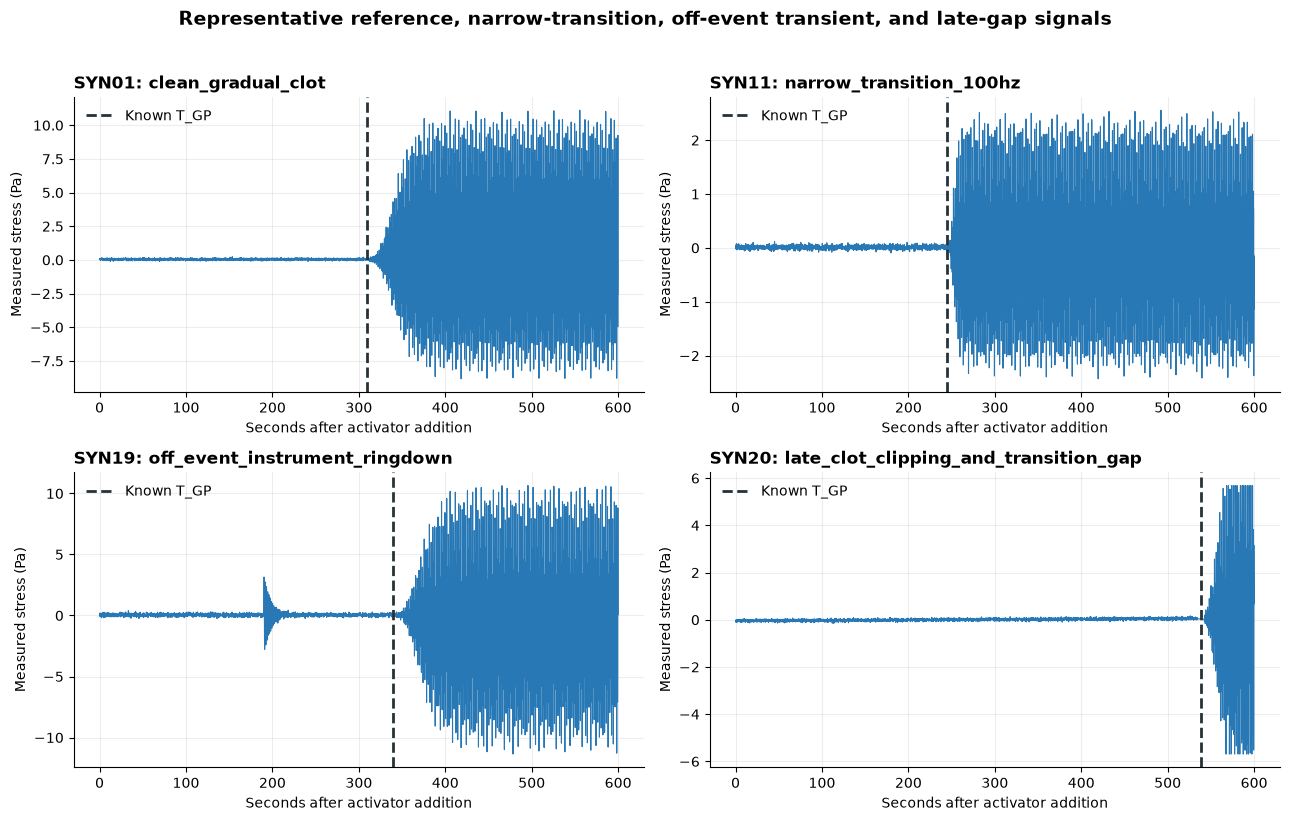

In [19]:
# Plotting representative observed stress signals and known clot times
selected_datasets = ["SYN01","SYN11","SYN19","SYN20"]
figure, axes = plt.subplots(2, 2, figsize=(13, 8))
for axis, dataset_id in zip(axes.ravel(), selected_datasets):
    record = next(row for row in manifest_records if row["dataset_id"] == dataset_id)
    observations = pd.read_csv(get_scenario_data_path(record))
    run_id = f"{dataset_id}_R01"
    selected = observations[observations["run_id"].eq(run_id)]
    truth_time = float(truth_lookup.loc[run_id, "ground_truth_gel_time_s"])
    skip = max(1, int(round(float(selected["nominal_sampling_rate_hz"].iloc[0]) / 8.0)))
    axis.plot(selected["time_s"].to_numpy()[::skip], selected["stress_measured_pa"].to_numpy()[::skip], color="#2878B5", lw=0.8)
    axis.axvline(truth_time, color=plot_colours["Truth"], ls="--", lw=2, label="Known T_GP")
    axis.set_title(f'{dataset_id}: {record["scenario_name"]}', loc="left")
    axis.set_xlabel("Seconds after activator addition")
    axis.set_ylabel("Measured stress (Pa)")
    axis.legend(frameon=False)
figure.suptitle("Representative reference, narrow-transition, off-event transient, and late-gap signals", y=1.02, fontsize=14, fontweight="bold")
figure.tight_layout()
figure.savefig(figure_directory / "01_observed_signals.png", dpi=180, bbox_inches="tight")
plt.show()

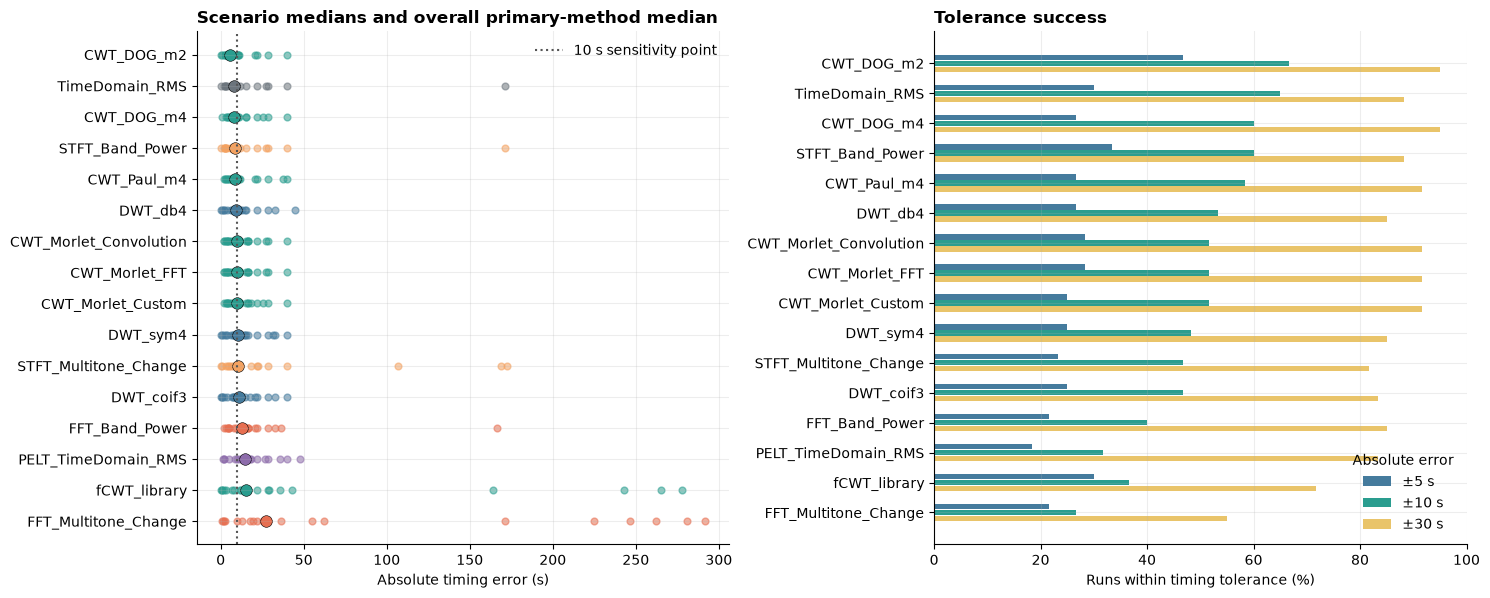

In [20]:
# Plotting method timing error and tolerance success
ordered_summary = primary_summary.sort_values("median_absolute_error_s")
figure, axes = plt.subplots(1, 2, figsize=(15, max(6, 0.38 * len(ordered_summary))))
for row_index, row in enumerate(ordered_summary.itertuples(index=False)):
    family_colour = plot_colours.get(row.method_family, plot_colours["Baseline"])
    scenario_values = scenario_summary.loc[
        scenario_summary["method"].eq(row.method),
        "scenario_median_absolute_error_s",
    ].dropna().to_numpy()
    axes[0].scatter(scenario_values, np.full(len(scenario_values), row_index), s=24, alpha=0.55, color=family_colour)
    axes[0].scatter(row.median_absolute_error_s, row_index, s=70, color=family_colour, edgecolor="black", linewidth=0.4)
axes[0].set_yticks(np.arange(len(ordered_summary)))
axes[0].set_yticklabels(ordered_summary["method"])
axes[0].invert_yaxis()
axes[0].set_xlabel("Absolute timing error (s)")
axes[0].set_title("Scenario medians and overall primary-method median", loc="left")
axes[0].axvline(10, color="#555555", ls=":", label="10 s sensitivity point")
axes[0].legend(frameon=False)

y_positions = np.arange(len(ordered_summary))
for offset, column, label, colour in [
    (-0.20,"within_5s","±5 s","#457B9D"),
    (0.00,"within_10s","±10 s","#2A9D8F"),
    (0.20,"within_30s","±30 s","#E9C46A"),
]:
    axes[1].barh(y_positions + offset, ordered_summary[column] * 100, height=0.18, label=label, color=colour)
axes[1].set_yticks(y_positions)
axes[1].set_yticklabels(ordered_summary["method"])
axes[1].invert_yaxis()
axes[1].set_xlim(0,100)
axes[1].set_xlabel("Runs within timing tolerance (%)")
axes[1].set_title("Tolerance success", loc="left")
axes[1].legend(title="Absolute error", frameon=False)
figure.tight_layout()
figure.savefig(figure_directory / "02_timing_and_tolerance.png", dpi=180, bbox_inches="tight")
plt.show()

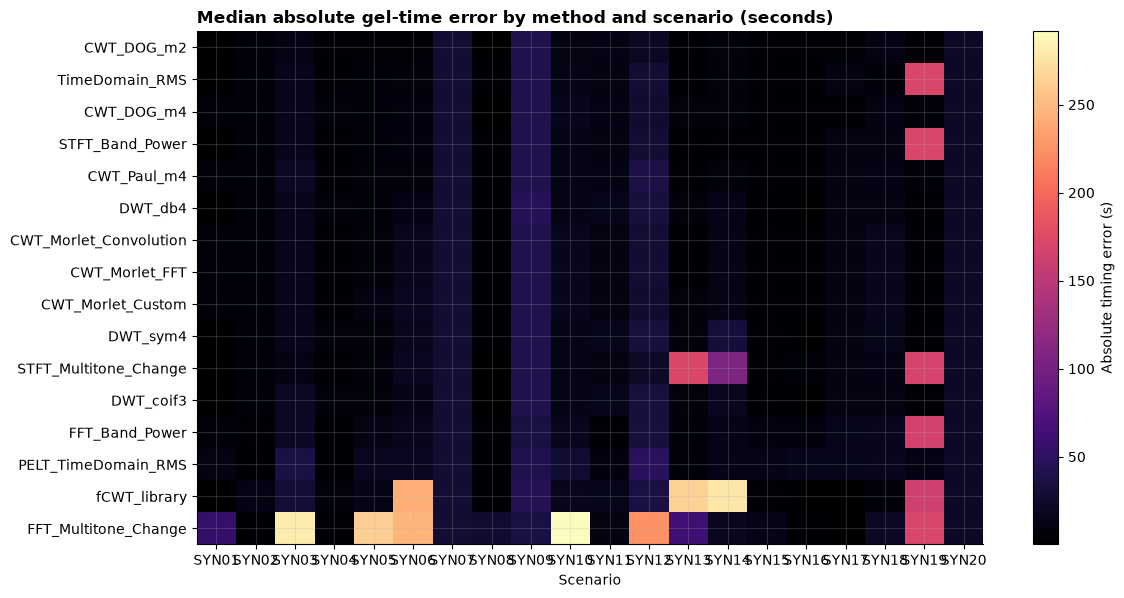

In [21]:
# Plotting per-scenario error to reveal failure modes hidden by the overall median
heatmap = scenario_summary.pivot(index="method", columns="dataset_id", values="scenario_median_absolute_error_s")
heatmap = heatmap.reindex(ordered_summary["method"])
figure, axis = plt.subplots(figsize=(12, max(6, 0.38 * len(heatmap))))
image = axis.imshow(heatmap.to_numpy(), aspect="auto", cmap="magma", interpolation="nearest")
axis.set_xticks(np.arange(len(heatmap.columns)))
axis.set_xticklabels(heatmap.columns)
axis.set_yticks(np.arange(len(heatmap.index)))
axis.set_yticklabels(heatmap.index)
axis.set_xlabel("Scenario")
axis.set_title("Median absolute gel-time error by method and scenario (seconds)", loc="left")
figure.colorbar(image, ax=axis, label="Absolute timing error (s)")
figure.tight_layout()
figure.savefig(figure_directory / "03_error_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

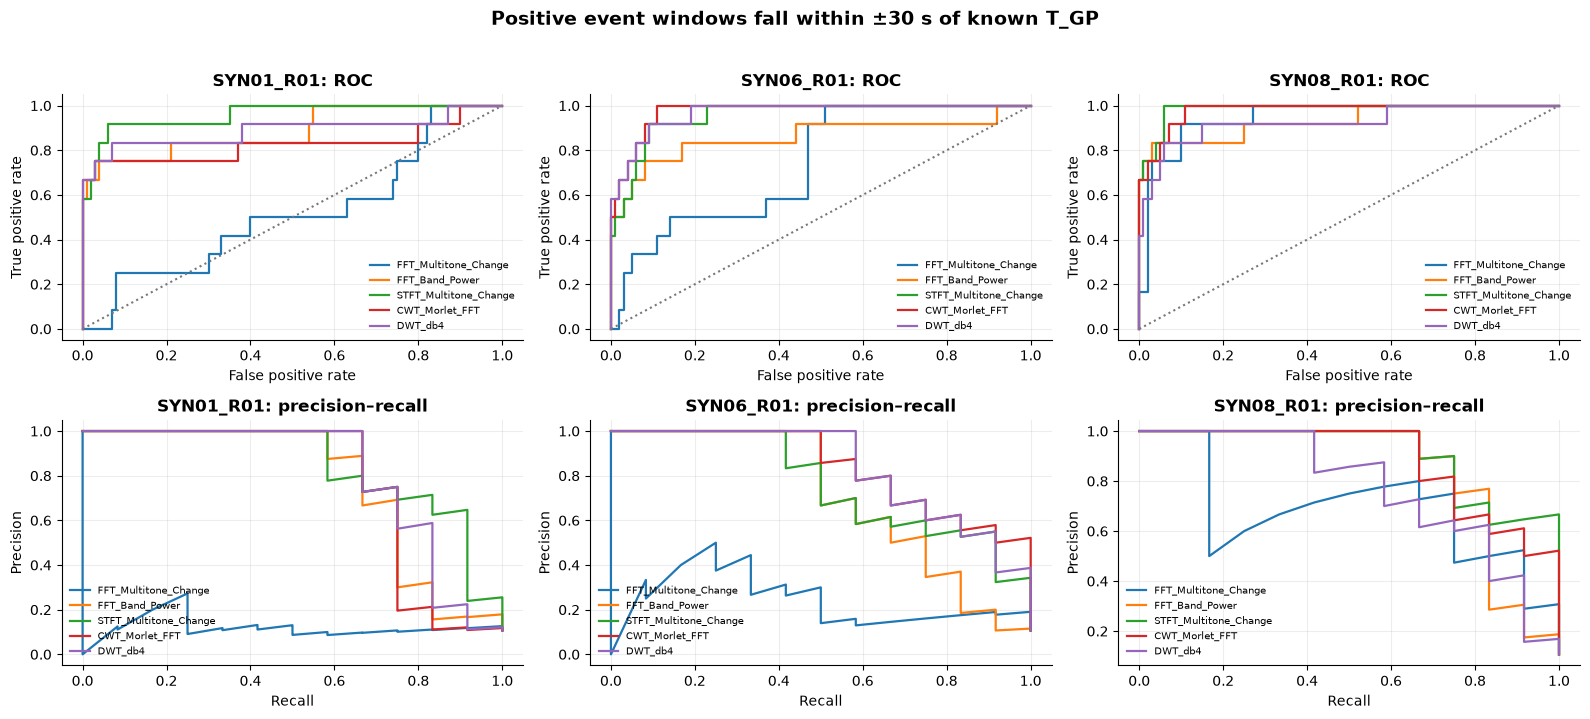

In [22]:
# Plotting event-window ROC and precision-recall curves on three distinct signals
selected_run_ids = ["SYN01_R01","SYN06_R01","SYN08_R01"]
selected_methods = [
    name for name in ["FFT_Multitone_Change","FFT_Band_Power","STFT_Multitone_Change","CWT_Morlet_FFT","DWT_db4"]
    if name in family_by_method
]
figure, axes = plt.subplots(2, 3, figsize=(16, 7))
for column, run_id in enumerate(selected_run_ids):
    this_run = window_scores[window_scores["run_id"].eq(run_id)]
    for method in selected_methods:
        values = this_run[
            this_run["method"].eq(method) & this_run["window_valid"] & this_run["event_score"].notna()
        ]
        labels = values["event_window_positive"].to_numpy(dtype=bool)
        scores = values["event_score"].to_numpy(dtype=float)
        if len(np.unique(labels)) < 2:
            continue
        false_positive, true_positive, _ = roc_curve(labels, scores)
        precision, recall, _ = precision_recall_curve(labels, scores)
        axes[0,column].plot(false_positive, true_positive, lw=1.6, label=method)
        axes[1,column].plot(recall, precision, lw=1.6, label=method)
    axes[0,column].plot([0,1],[0,1], color="#777777", ls=":")
    axes[0,column].set_title(f"{run_id}: ROC")
    axes[0,column].set_xlabel("False positive rate")
    axes[0,column].set_ylabel("True positive rate")
    axes[1,column].set_title(f"{run_id}: precision–recall")
    axes[1,column].set_xlabel("Recall")
    axes[1,column].set_ylabel("Precision")
    axes[0,column].legend(fontsize=7, frameon=False, loc="lower right")
    axes[1,column].legend(fontsize=7, frameon=False, loc="lower left")
figure.suptitle("Positive event windows fall within ±30 s of known T_GP", y=1.02, fontsize=14, fontweight="bold")
figure.tight_layout()
figure.savefig(figure_directory / "04_event_window_curves.png", dpi=180, bbox_inches="tight")
plt.show()

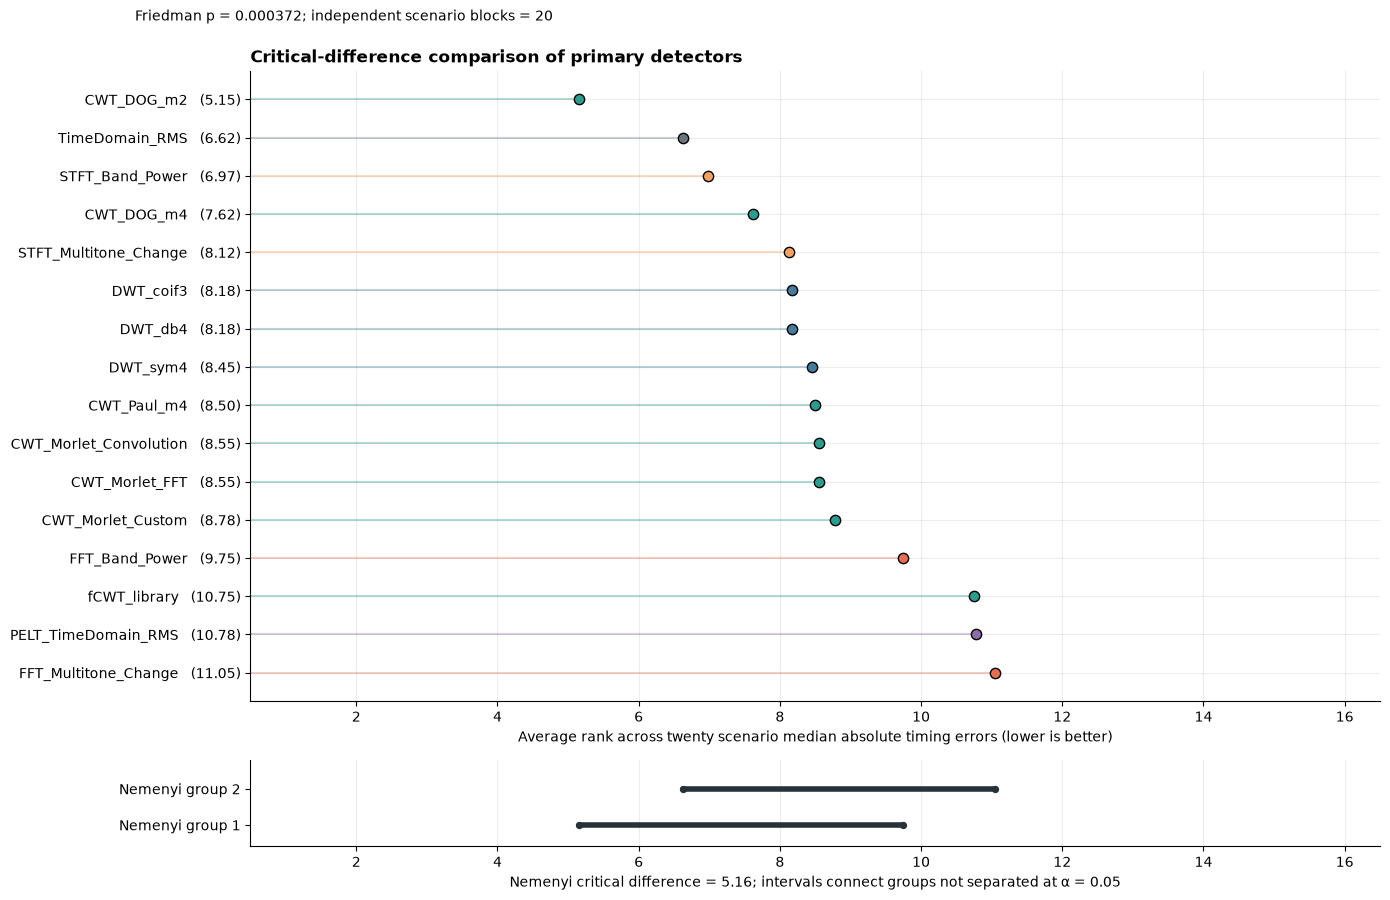

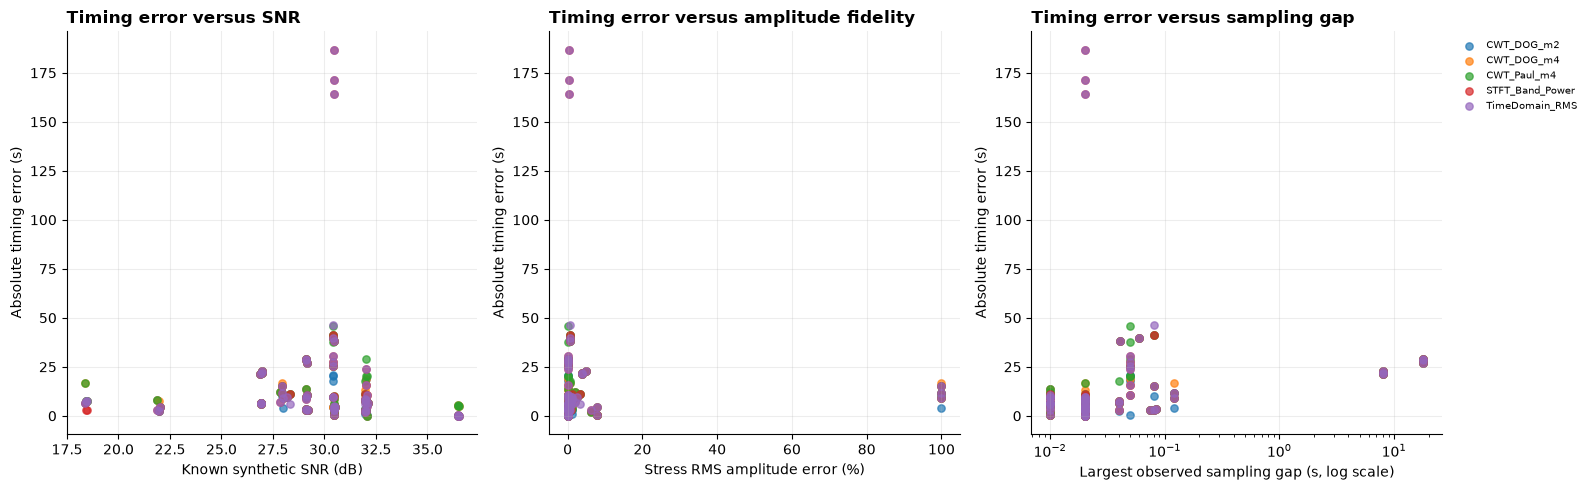

In [23]:
# Creating a readable critical-difference rank view for primary methods
rank_matrix = error_matrix[complete_methods].rank(axis=1, method="average", ascending=True)
average_ranks = rank_matrix.mean(axis=0).sort_values()
critical_difference = np.nan
try:
    from scipy.stats import studentized_range
    q_critical = studentized_range.ppf(0.95, len(average_ranks), np.inf) / np.sqrt(2.0)
    critical_difference = float(q_critical * np.sqrt(
        len(average_ranks) * (len(average_ranks)+1) / (6.0 * len(rank_matrix))
    ))
except Exception:
    pass

sorted_methods = average_ranks.index.to_list()
method_positions = np.arange(len(sorted_methods))
figure, (rank_axis, group_axis) = plt.subplots(
    2, 1, figsize=(14, 9), gridspec_kw={"height_ratios":[len(sorted_methods), 2.2]}
)
for method_position, method_name in enumerate(sorted_methods):
    rank_value = float(average_ranks[method_name])
    family = family_by_method.get(method_name, "Baseline")
    family_colour = plot_colours.get(family, plot_colours["Baseline"])
    rank_axis.hlines(method_position, 0.5, rank_value, color=family_colour, alpha=0.35, linewidth=1.5)
    rank_axis.scatter(rank_value, method_position, color=family_colour, edgecolor="black", s=55, zorder=3)

rank_axis.set_yticks(method_positions)
rank_axis.set_yticklabels([f"{method}   ({average_ranks[method]:.2f})" for method in sorted_methods])
rank_axis.invert_yaxis()
rank_axis.set_xlim(0.5, len(average_ranks)+0.5)
rank_axis.set_xlabel("Average rank across twenty scenario median absolute timing errors (lower is better)")
rank_axis.set_title("Critical-difference comparison of primary detectors", loc="left")

nonsignificant_groups = []
for group_start in range(len(sorted_methods)):
    for group_end in range(group_start + 1, len(sorted_methods)):
        rank_span = average_ranks.iloc[group_end] - average_ranks.iloc[group_start]
        if np.isfinite(critical_difference) and rank_span <= critical_difference:
            nonsignificant_groups.append((group_start, group_end))
maximal_groups = [
    group for group in nonsignificant_groups
    if not any(group[0] >= other[0] and group[1] <= other[1] and group != other for other in nonsignificant_groups)
]
for group_position, (group_start, group_end) in enumerate(maximal_groups):
    left_rank = float(average_ranks.iloc[group_start])
    right_rank = float(average_ranks.iloc[group_end])
    group_axis.plot([left_rank, right_rank], [group_position, group_position], color="#263238", lw=4, solid_capstyle="round")
    group_axis.scatter([left_rank, right_rank], [group_position, group_position], color="#263238", s=18)

group_axis.set_xlim(0.5, len(average_ranks)+0.5)
group_axis.set_ylim(-0.6, max(len(maximal_groups),1)-0.2)
group_axis.set_yticks(np.arange(len(maximal_groups)))
group_axis.set_yticklabels([f"Nemenyi group {group_number}" for group_number in range(1,len(maximal_groups)+1)])
group_axis.set_xlabel(f"Nemenyi critical difference = {critical_difference:.2f}; intervals connect groups not separated at α = 0.05")
group_axis.grid(axis="y", visible=False)
figure.suptitle(f"Friedman p = {friedman_p:.3g}; independent scenario blocks = {len(rank_matrix)}", x=0.10, y=0.995, ha="left", fontsize=10)
figure.tight_layout()
figure.savefig(figure_directory / "05_critical_difference.png", dpi=180, bbox_inches="tight")
plt.show()

quality_join = available.merge(
    quality_table[["run_id","dataset_id","known_snr_db","sampling_interval_cv","missing_fraction","clipped_fraction","stress_rms_amplitude_error_percent","maximum_observed_gap_s","unit_scale_fault"]],
    on=["run_id","dataset_id"], how="left",
)
top_methods = primary_summary.head(5)["method"].tolist()
quality_join = quality_join[quality_join["method"].isin(top_methods)].copy()
figure, axes = plt.subplots(1,3,figsize=(16,5))
for method, method_rows in quality_join.groupby("method"):
    axes[0].scatter(method_rows["known_snr_db"],method_rows["absolute_timing_error_s"],s=28,alpha=0.7,label=method)
    axes[1].scatter(method_rows["stress_rms_amplitude_error_percent"],method_rows["absolute_timing_error_s"],s=28,alpha=0.7,label=method)
    axes[2].scatter(method_rows["maximum_observed_gap_s"],method_rows["absolute_timing_error_s"],s=28,alpha=0.7,label=method)
axes[0].set_xlabel("Known synthetic SNR (dB)")
axes[0].set_ylabel("Absolute timing error (s)")
axes[0].set_title("Timing error versus SNR",loc="left")
axes[1].set_xlabel("Stress RMS amplitude error (%)")
axes[1].set_ylabel("Absolute timing error (s)")
axes[1].set_title("Timing error versus amplitude fidelity",loc="left")
axes[2].set_xscale("log")
axes[2].set_xlabel("Largest observed sampling gap (s, log scale)")
axes[2].set_ylabel("Absolute timing error (s)")
axes[2].set_title("Timing error versus sampling gap",loc="left")
axes[2].legend(fontsize=7,frameon=False,bbox_to_anchor=(1.02,1),loc="upper left")
figure.tight_layout()
figure.savefig(figure_directory / "06_quality_robustness.png",dpi=180,bbox_inches="tight")
plt.show()


## Window-length sensitivity

The main comparison fixes the analysis window at 40 seconds for every method. This targeted sensitivity check repeats the same detectors with 20-, 40-, and 60-second windows on a clean reference, a narrow clot transition, an off-event ringdown, and a late event with a transition gap. Every method keeps the same 5-second hop and shared validity rule within a window-length setting.

The shorter window may better localize fast changes but can reduce low-frequency wavelet support; the longer window may stabilize spectral estimates while smoothing a short transition. These results are reported separately from the primary ranking and are not used to choose the best primary window after looking at the outcome.


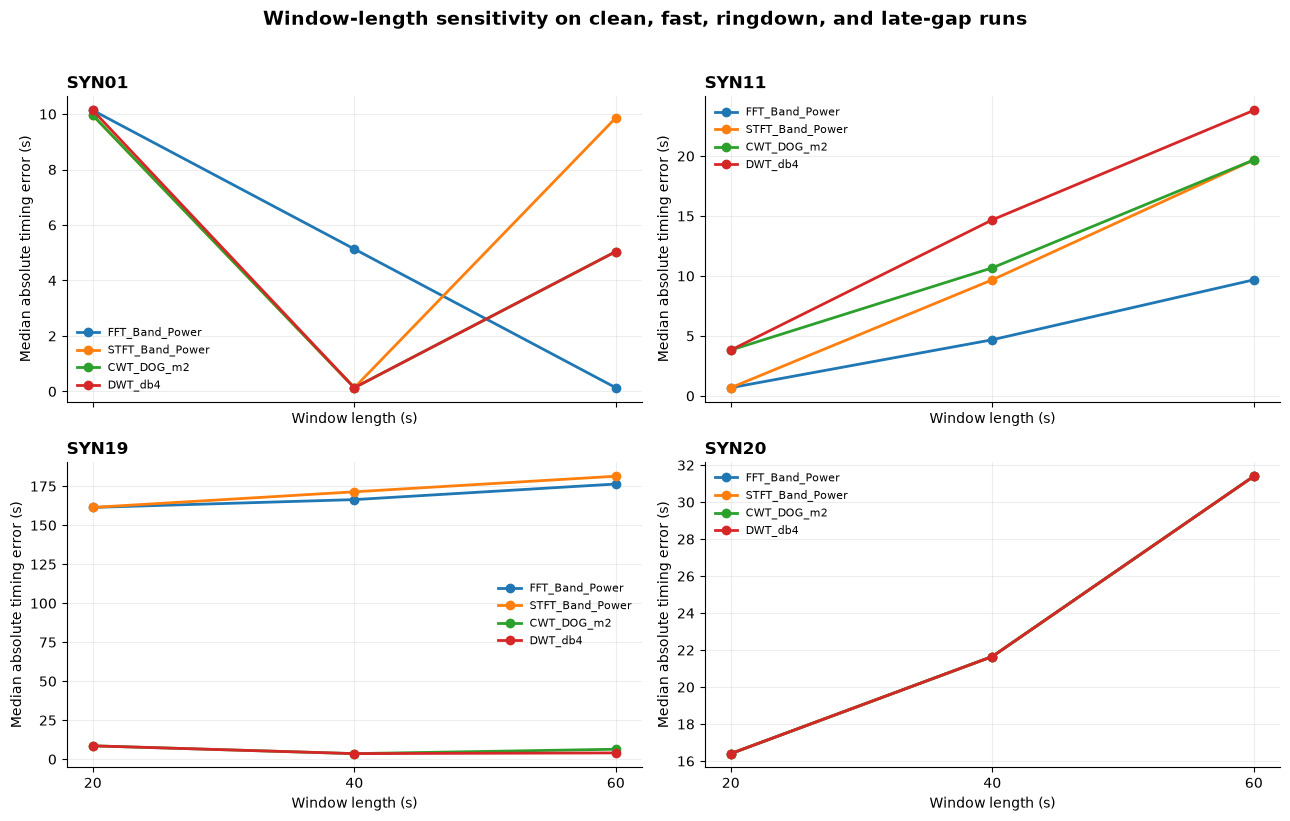

,dataset_id,method,window_length_s,median_absolute_error_s,median_roc_auc,within_10s,no_call_fraction
0,SYN01,CWT_DOG_m2,20.0,9.96,0.92,0.67,0.0
1,SYN01,CWT_DOG_m2,40.0,0.13,0.95,1.00,0.0
2,SYN01,CWT_DOG_m2,60.0,5.04,1.00,1.00,0.0
3,SYN01,DWT_db4,20.0,10.13,0.89,0.33,0.0
4,SYN01,DWT_db4,40.0,0.13,0.91,1.00,0.0
5,SYN01,DWT_db4,60.0,5.04,0.95,0.67,0.0
6,SYN01,FFT_Band_Power,20.0,10.13,0.86,0.33,0.0
7,SYN01,FFT_Band_Power,40.0,5.13,0.91,1.00,0.0
8,SYN01,FFT_Band_Power,60.0,0.13,0.95,1.00,0.0
9,SYN01,STFT_Band_Power,20.0,9.96,0.90,0.67,0.0


In [24]:
# Comparing window lengths on four predefined signal conditions
original_window_seconds = window_seconds
sensitivity_window_lengths_seconds = [20.0, 40.0, 60.0]
sensitivity_dataset_ids = ["SYN01", "SYN11", "SYN19", "SYN20"]
sensitivity_method_names = [
    "FFT_Band_Power", "STFT_Band_Power", "CWT_DOG_m2", "DWT_db4"
]
configuration_lookup = {
    configuration["dataset_id"]: configuration
    for configuration in scenario_configurations
}
truth_lookup = truth_table.set_index("run_id")
sensitivity_records = []

try:
    for sensitivity_dataset_id in sensitivity_dataset_ids:
        scenario_record = next(
            manifest_record for manifest_record in manifest_records
            if manifest_record["dataset_id"] == sensitivity_dataset_id
        )
        scenario_observations = pd.read_csv(get_scenario_data_path(scenario_record))
        scenario_configuration = configuration_lookup[sensitivity_dataset_id]

        for sensitivity_run_id, sensitivity_run_frame in scenario_observations.groupby("run_id", sort=True):
            known_gel_time_s = float(
                truth_lookup.loc[sensitivity_run_id, "ground_truth_gel_time_s"]
            )

            for sensitivity_window_length_s in sensitivity_window_lengths_seconds:
                window_seconds = sensitivity_window_length_s
                prepared_sensitivity_run = prepare_run(sensitivity_run_frame)
                sensitivity_feature_frame = extract_features(
                    prepared_sensitivity_run, scenario_configuration
                )

                for sensitivity_method_name in sensitivity_method_names:
                    sensitivity_result, _ = evaluate_method(
                        sensitivity_method_name,
                        sensitivity_feature_frame,
                        known_gel_time_s,
                        sensitivity_run_id,
                        sensitivity_dataset_id,
                    )
                    sensitivity_result["window_length_s"] = sensitivity_window_length_s
                    sensitivity_records.append(sensitivity_result)
finally:
    window_seconds = original_window_seconds

window_sensitivity_results = pd.DataFrame(sensitivity_records)
window_sensitivity_results.to_csv(
    output_directory / "window_length_sensitivity_by_run.csv", index=False
)
window_sensitivity_summary = (
    window_sensitivity_results.groupby(
        ["dataset_id", "method", "window_length_s"], as_index=False
    )
    .agg(
        median_absolute_error_s=("absolute_timing_error_s", "median"),
        median_roc_auc=("roc_auc_event_window", "median"),
        within_10s=("absolute_timing_error_s", lambda values: float(values.le(10.0).mean())),
        no_call_fraction=("no_call", "mean"),
    )
)
window_sensitivity_summary.to_csv(
    output_directory / "window_length_sensitivity_summary.csv", index=False
)

figure, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for sensitivity_axis, sensitivity_dataset_id in zip(axes.ravel(), sensitivity_dataset_ids):
    dataset_sensitivity_summary = window_sensitivity_summary[
        window_sensitivity_summary["dataset_id"].eq(sensitivity_dataset_id)
    ]
    for sensitivity_method_name in sensitivity_method_names:
        method_sensitivity = dataset_sensitivity_summary[
            dataset_sensitivity_summary["method"].eq(sensitivity_method_name)
        ].sort_values("window_length_s")
        sensitivity_axis.plot(
            method_sensitivity["window_length_s"],
            method_sensitivity["median_absolute_error_s"],
            marker="o", linewidth=2, label=sensitivity_method_name,
        )
    sensitivity_axis.set_title(sensitivity_dataset_id, loc="left")
    sensitivity_axis.set_xlabel("Window length (s)")
    sensitivity_axis.set_ylabel("Median absolute timing error (s)")
    sensitivity_axis.set_xticks(sensitivity_window_lengths_seconds)
    sensitivity_axis.legend(frameon=False, fontsize=8)
figure.suptitle(
    "Window-length sensitivity on clean, fast, ringdown, and late-gap runs",
    y=1.02, fontsize=14, fontweight="bold",
)
figure.tight_layout()
figure.savefig(figure_directory / "07_window_length_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()
display(window_sensitivity_summary.round(2))


## Validation, reporting tables, instrument-scale comparison, and limitations

The validation table checks the twenty regenerated scenario manifests, per-replicate row counts, separate labels, exact trajectory midpoint, and whether the primary methods returned predictions. Synthetic SNR and amplitude fidelity use latent clean signals and injected noise, so these are simulator audits rather than quantities available in a clinical run.

A separate scale check compares robust stress and strain ranges in the synthetic measurements with measured Haemograph blood-rheology records. Those source files contain different steady, step, and oscillatory protocols; the comparison can reveal scale mismatches but cannot validate synthetic clot kinetics or define a sensor noise floor. Synthetic parameters remain design choices unless separately calibrated against instrument specifications and matched protocols.

The primary 40-second window and 5-second hop set the timing granularity. A separate 20/40/60-second sensitivity analysis checks how window width changes timing error in four predefined conditions. A ±5-second result is near the hop resolution and should not be interpreted as independently validated clinical accuracy. Event-window ROC/PR and gel-time prediction remain separate outcomes. Twenty scenario families provide twenty blocks for rank tests, but these are intentionally selected conditions rather than a random population sample.

Chirp-specific mutation-number and time–bandwidth thresholds are outside this multisine design. ADF stationarity is not a hard gate because the intended clot signal evolves over time. CWT and DWT edge handling and decomposition parameters are recorded in the transform table. fCWT results are only reported if the package loads and returns finite outputs.

In [25]:
# Saving validation checks, transform settings, feature definitions, and reporting table
validation = pd.DataFrame([
    ["Twenty scenario files",len(manifest_table)==20,len(manifest_table)],
    ["Every scenario has at least 10,000 rows",bool((manifest_table["retained_rows"]>=10000).all()),int(manifest_table["retained_rows"].min())],
    ["Every replicate has at least 10,000 rows",bool((manifest_table["minimum_rows_per_replicate"]>=10000).all()),int(manifest_table["minimum_rows_per_replicate"].min())],
    ["Sixty separate known gel-time labels",truth_table["run_id"].nunique()==60,truth_table["run_id"].nunique()],
    ["All generated trajectories equal 0.5 at their labelled gel time",bool(np.allclose(truth_table["progress_at_ground_truth"],0.5,atol=1e-8)),float(np.max(np.abs(truth_table["progress_at_ground_truth"]-0.5)))],
    ["Unit-scale fault is tagged",bool(quality_table["unit_scale_fault"].any()),int(quality_table["unit_scale_fault"].sum())],
    ["Timing-window calculations retain gaps",bool(quality_table["maximum_observed_gap_s"].notna().all()),float(quality_table["maximum_observed_gap_s"].max())],
    ["Ground truth stored outside observed CSVs",(output_directory/"ground_truth_labels.csv").exists(),"separate label file"],
    ["All primary methods have scenario-level scores",bool(primary_summary["median_absolute_error_s"].notna().all()),int(primary_summary["method"].nunique())],
    ["Window sensitivity covers each predefined condition",window_sensitivity_results["dataset_id"].nunique()==4,int(window_sensitivity_results["dataset_id"].nunique())],
],columns=["validation_check","passed","observed"])
validation.to_csv(output_directory/"validation_checks.csv",index=False)

settings = pd.DataFrame([
    ["Primary shared outer windows","40 s; 5 s hop","All methods share window centers and the same gap-based validity mask."],
    ["Window-length sensitivity","20 s, 40 s, and 60 s; 5 s hop","Four predefined scenarios; reported separately from the primary ranking."],
    ["Scenario design","20 scenarios; 3 replicates each","All twenty scenario families are regenerated by one corrected simulator version in v2_data."],
    ["Gel-time boundary cases","Early, central, and late event positions","SYN04 is an early event; SYN09 and SYN20 provide late-event conditions with limited or missing support."],
    ["Irregular-time handling","Linear interpolation to nominal sampling grid","Observed gaps above 2 s invalidate the same windows for every method."],
    ["Main preprocessing","Window-wise mean removal","Linear drift and slow baseline wander remain as robustness challenges."],
    ["FFT/STFT","Hann taper; 0.15 Hz to min(8 Hz, 0.40 × sample rate)","Multitone channels use drive frequencies and supported harmonics; STFT uses a 4 s inner segment and 75% overlap."],
    ["CWT families","Morlet, Paul m=4, DOG m=2 and m=4","Torrence and Compo (1998), Eq. 1, convolution Eqs. 2–4, Table 1, pp. 62–64; measured frequencies, channel-specific support trimming."],
    ["Fast CWT","PyWavelets Morlet method=fft and method=conv","Optional fcwt package is kept separately; actual load and runtime status are exported."],
    ["DWT bases","db4, sym4, coif3; up to level 6","Mallat (1989), multiresolution signal decomposition; symmetric extension; detail energy retained by level."],
    ["Shared detector score","Robustly scaled absolute channel derivatives","Same centering, scaling, smoothing, and RMS combination across all transform families; label-blind."],
    ["PELT","L2 cost; penalty 2 × variance × log(window count)","Explicit benchmark setting, not a literature acceptance threshold."],
    ["Statistical comparisons","Friedman, Holm-adjusted Wilcoxon, Nemenyi CD","Demšar (2006), §§3.1.3, 3.2.2, 3.2.4; twenty designed scenario blocks."],
    ["Timing tolerances","±5, ±10, ±30 s","Sensitivity points, not confirmed clinical thresholds."],
    ["Detector scope","Retrospective full-record maximum","Run-level robust scaling and maximum-score selection use the complete recording; no streaming alarm threshold is applied."],
    ["ROC and average precision","Windows within ±30 s of T_GP","Secondary event-localization summaries; 40 s windows at 5 s hops overlap and are not independent observations."],
    ["Instrument-scale check","Measured workbook records versus synthetic stress/strain ranges","Scale-only comparison across different protocols; not clot-kinetics validation or sensor-noise calibration."],
],columns=["setting","configuration","handling"])
settings.to_csv(output_directory/"transform_parameter_table.csv",index=False)

dictionary = pd.DataFrame([
    ["TimeDomain_RMS","Log stress RMS in the shared window","Baseline signal magnitude change."],
    ["FFT_Band_Power","Log Hann-windowed broad-band Fourier energy","Global Fourier energy-change baseline."],
    ["FFT_Multitone_Change","Per-tone and supported-harmonic Fourier power channels","Frequency-specific global spectra summarized with the shared multichannel change score."],
    ["FFT_H3_over_H1","Log third-to-first harmonic ratio","Secondary nonlinear-response descriptor; excluded from primary timing ranks because third-harmonic injection is part of the simulator."],
    ["STFT_Multitone_Change","Per-tone and harmonic short-time Fourier power channels","Localized frequency-energy changes summarized with the shared score."],
    ["CWT family outputs","Log coefficient energy retained separately by matched frequency scale","Time-localized scale-energy changes; actual drive frequencies plus supported harmonics."],
    ["DWT family outputs","Log detail-coefficient energy retained by decomposition level","Multiresolution changes by level; symmetric boundary extension."],
    ["fCWT_library","Log coefficient power at closest returned frequency channels","Optional external fast CWT; unavailable or failed runs are explicitly marked."],
    ["Fourier_Winter_Chambon","Negative operational mismatch of fitted slopes, phase spread, and power-law fits","Criterion-aligned positive control; excluded from primary ranking because the synthetic truth uses this condition."],
    ["Fourier_Gprime_Gdoubleprime_Crossover","Negative absolute log ratio of G′ and G″ at the lowest shared frequency","Secondary rheological comparator; not the primary truth definition."],
    ["ROC AUC and average precision","Window-score discrimination for labels within ±30 s of T_GP","Secondary localization metrics on overlapping windows; not gel-time error or classifier accuracy."],
    ["Stress RMS amplitude error and SNR","Differences between known clean simulated stress and measured stress/noise","Simulator signal-fidelity audits; not observable clinical measurements."],
    ["Runtime","Median feature extraction and detector time per run, in ms","Environment-dependent; compare methods on the same machine and software stack."],
    ["Spearman rho","Rank association between predicted and true gel time","Ordering only; not agreement or calibration."],
],columns=["feature_or_metric","definition","interpretation"])
dictionary.to_csv(output_directory/"feature_dictionary.csv",index=False)

report_table = summary.sort_values("median_absolute_error_s")
report_table.to_csv(output_directory/"reporting_table.csv",index=False)
display(validation)
print(f"Rows across the twenty scenarios: {manifest_table['retained_rows'].sum():,}")
print(f"Tables and figures saved under {output_directory}")
print(f"fCWT library status: {fcwt_status}")
display(report_table.round(3))


,validation_check,passed,observed
0,Twenty scenario files,True,20
1,"Every scenario has at least 10,000 rows",True,54000
2,"Every replicate has at least 10,000 rows",True,18000
3,Sixty separate known gel-time labels,True,60
4,All generated trajectories equal 0.5 at their ...,True,0.0
5,Unit-scale fault is tagged,True,3
6,Timing-window calculations retain gaps,True,18.031859
7,Ground truth stored outside observed CSVs,True,separate label file
8,All primary methods have scenario-level scores,True,16
9,Window sensitivity covers each predefined cond...,True,4


Rows across the twenty scenarios: 2,116,097
Tables and figures saved under /Users/riamishra/Desktop/Haemograph_Project/Syn_code_new/v2_outputs
fCWT library status: available


,method,method_family,comparison_role,median_absolute_error_s,mean_absolute_error_s,median_signed_error_s,median_roc_auc_event_window,median_average_precision_event_window,no_call_fraction,median_feature_runtime_ms,within_5s,within_10s,within_30s,spearman_rho,scenario_bootstrap_ci_2_5_s,scenario_bootstrap_ci_97_5_s
0,CWT_DOG_m2,CWT,Primary timing benchmark,5.868,9.717,3.259,0.972,0.878,0.0,131.615,0.467,0.667,0.950,0.994,3.379,10.588
1,Fourier_Winter_Chambon,Fourier,Criterion-aligned positive control; excluded f...,6.547,18.574,-0.889,0.990,0.926,0.0,57.634,0.333,0.633,0.950,0.908,4.534,10.074
2,TimeDomain_RMS,Baseline,Primary timing benchmark,7.770,19.538,4.375,0.960,0.839,0.0,0.787,0.300,0.650,0.883,0.922,5.198,13.613
3,CWT_DOG_m4,CWT,Primary timing benchmark,7.973,11.831,5.684,0.971,0.865,0.0,130.510,0.267,0.600,0.950,0.995,6.173,13.221
4,Fourier_Gprime_Gdoubleprime_Crossover,Fourier,Secondary rheological comparator; excluded fro...,8.362,25.060,-0.889,0.641,0.646,0.0,57.633,0.383,0.533,0.817,0.897,4.505,13.438
5,STFT_Band_Power,STFT,Primary timing benchmark,8.581,19.538,3.405,0.952,0.847,0.0,27.237,0.333,0.600,0.883,0.922,3.586,13.565
6,CWT_Paul_m4,CWT,Primary timing benchmark,8.841,12.893,6.906,0.961,0.853,0.0,164.563,0.267,0.583,0.917,0.993,5.544,11.415
7,DWT_db4,DWT,Primary timing benchmark,9.492,23.521,6.660,0.945,0.821,0.0,6.889,0.267,0.533,0.850,0.864,6.525,13.714
9,CWT_Morlet_FFT,CWT,Primary timing benchmark,9.581,15.375,5.684,0.947,0.809,0.0,210.050,0.283,0.517,0.917,0.963,4.720,16.186
8,CWT_Morlet_Convolution,CWT,Primary timing benchmark,9.581,15.375,5.684,0.947,0.809,0.0,967.077,0.283,0.517,0.917,0.963,4.720,16.186


## Instrument-scale reference check

This check extracts stress, strain, and sampling summaries from the measured LAOS, UDLAOS, and step records in the project's Haemograph workbook folder. It compares the stress scale with the synthetic runs. The protocols differ, so the comparison is descriptive and does not validate clot kinetics or estimate an instrument noise floor.

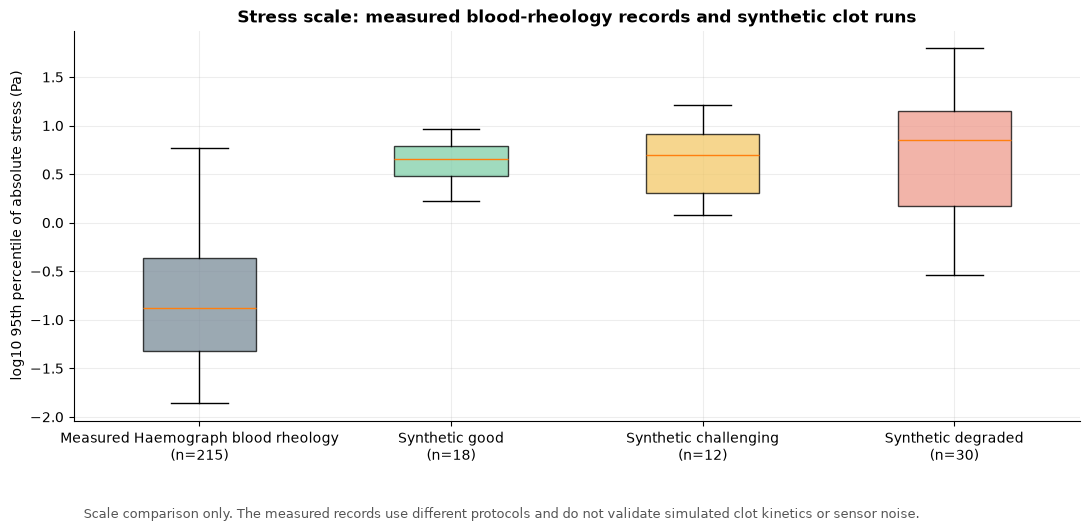

,record_source,record_count,stress_p95_abs_pa_median,stress_p95_abs_pa_p10,stress_p95_abs_pa_p90,stress_rms_pa_median,strain_p95_abs_fraction_median,median_sampling_interval_s_median,stress_scale_ratio_to_measured_median
0,Measured Haemograph blood rheology,215,0.1311,0.0255,1.1634,0.0839,9.9722,0.02,1.0000
1,Synthetic challenging,12,5.0221,1.6656,14.9038,2.2731,0.0125,0.02,38.3146
2,Synthetic degraded,30,7.0448,0.0095,43.7881,3.0765,0.0166,0.02,53.7463
3,Synthetic good,18,4.4869,1.8313,7.3043,1.8621,0.0147,0.02,34.2317


In [26]:
# Comparing instrument-scale stress and strain with measured records
instrument_record_rows = []
failed_instrument_files = []


def summarize_instrument_trace(raw_sheet, workbook_name, sheet_name, first_column):
    time_values = pd.to_numeric(raw_sheet.iloc[3:, first_column], errors="coerce")
    stress_values = pd.to_numeric(raw_sheet.iloc[3:, first_column + 1], errors="coerce")
    strain_values = pd.to_numeric(raw_sheet.iloc[3:, first_column + 2], errors="coerce")
    trace_frame = pd.DataFrame({
        "time_s": time_values,
        "stress_pa": stress_values,
        "strain": strain_values,
    }).dropna()
    if len(trace_frame) < 8:
        return None

    ordered_frame = trace_frame.sort_values("time_s").drop_duplicates("time_s")
    if len(ordered_frame) < 8:
        return None
    sampling_intervals_s = np.diff(ordered_frame["time_s"].to_numpy(dtype=float))
    sampling_intervals_s = sampling_intervals_s[sampling_intervals_s > 0]
    if len(sampling_intervals_s) == 0:
        return None

    strain_units = str(raw_sheet.iloc[2, first_column + 2]).strip().lower()
    strain_values = ordered_frame["strain"].to_numpy(dtype=float)
    if strain_units in {"%", "percent"}:
        strain_values = strain_values / 100.0

    stress_values = ordered_frame["stress_pa"].to_numpy(dtype=float)
    return {
        "record_source": "Measured Haemograph blood rheology",
        "record_id": f"{workbook_name}:{sheet_name}:column_{first_column}",
        "sample_count": int(len(ordered_frame)),
        "duration_s": float(ordered_frame["time_s"].max() - ordered_frame["time_s"].min()),
        "median_sampling_interval_s": float(np.median(sampling_intervals_s)),
        "stress_rms_pa": float(np.sqrt(np.mean(stress_values ** 2))),
        "stress_p95_abs_pa": float(np.quantile(np.abs(stress_values), 0.95)),
        "strain_p95_abs_fraction": float(np.quantile(np.abs(strain_values), 0.95)),
        "protocol": sheet_name,
    }


if instrument_reference_directory.exists():
    instrument_workbook_paths = sorted(
        workbook_path for workbook_path in instrument_reference_directory.glob("*.xlsx")
        if not workbook_path.name.startswith("~$")
    )
    for instrument_workbook_path in instrument_workbook_paths:
        try:
            instrument_excel_file = pd.ExcelFile(instrument_workbook_path)
        except Exception as error:
            failed_instrument_files.append({
                "workbook": instrument_workbook_path.name,
                "error": f"{type(error).__name__}: {error}",
            })
            continue

        for protocol_sheet_name in ["LAOS", "UDLAOS", "Steps"]:
            if protocol_sheet_name not in instrument_excel_file.sheet_names:
                continue
            try:
                raw_protocol_sheet = instrument_excel_file.parse(protocol_sheet_name, header=None)
            except Exception as error:
                failed_instrument_files.append({
                    "workbook": instrument_workbook_path.name,
                    "sheet": protocol_sheet_name,
                    "error": f"{type(error).__name__}: {error}",
                })
                continue

            if raw_protocol_sheet.shape[0] < 8:
                continue
            header_values = raw_protocol_sheet.iloc[1].astype(str).str.strip().str.casefold()
            trace_start_columns = np.flatnonzero(header_values.eq("step time").to_numpy())
            for trace_start_column in trace_start_columns:
                if int(trace_start_column) + 2 >= raw_protocol_sheet.shape[1]:
                    continue
                trace_summary = summarize_instrument_trace(
                    raw_protocol_sheet,
                    instrument_workbook_path.name,
                    protocol_sheet_name,
                    int(trace_start_column),
                )
                if trace_summary is not None:
                    instrument_record_rows.append(trace_summary)
else:
    instrument_workbook_paths = []

measured_instrument_records = pd.DataFrame(instrument_record_rows)
synthetic_instrument_records = quality_table[[
    "run_id", "retained_rows", "median_sampling_interval_s", "stress_rms_pa",
    "stress_p95_abs_pa", "strain_p95_abs_fraction", "quality_status",
]].copy()
synthetic_instrument_records = synthetic_instrument_records.rename(columns={"run_id": "record_id"})
synthetic_instrument_records["record_source"] = "Synthetic " + synthetic_instrument_records["quality_status"].astype(str)
synthetic_instrument_records["sample_count"] = synthetic_instrument_records["retained_rows"]
synthetic_instrument_records["protocol"] = "Synthetic clot trajectory"
instrument_comparison_records = pd.concat([
    measured_instrument_records,
    synthetic_instrument_records.drop(columns=["retained_rows", "quality_status"], errors="ignore"),
], ignore_index=True, sort=False)
instrument_comparison_records.to_csv(
    output_directory / "instrument_scale_comparison_by_record.csv", index=False
)

instrument_scale_summary_rows = []
for source_name, source_records in instrument_comparison_records.groupby("record_source", sort=True):
    instrument_scale_summary_rows.append({
        "record_source": source_name,
        "record_count": int(len(source_records)),
        "stress_p95_abs_pa_median": float(source_records["stress_p95_abs_pa"].median()),
        "stress_p95_abs_pa_p10": float(source_records["stress_p95_abs_pa"].quantile(0.10)),
        "stress_p95_abs_pa_p90": float(source_records["stress_p95_abs_pa"].quantile(0.90)),
        "stress_rms_pa_median": float(source_records["stress_rms_pa"].median()),
        "strain_p95_abs_fraction_median": float(source_records["strain_p95_abs_fraction"].median()),
        "median_sampling_interval_s_median": float(source_records["median_sampling_interval_s"].median()),
    })
instrument_scale_summary = pd.DataFrame(instrument_scale_summary_rows)
measured_scale_median_pa = instrument_scale_summary.loc[
    instrument_scale_summary["record_source"].eq("Measured Haemograph blood rheology"),
    "stress_p95_abs_pa_median",
].squeeze() if instrument_scale_summary["record_source"].eq("Measured Haemograph blood rheology").any() else np.nan
instrument_scale_summary["stress_scale_ratio_to_measured_median"] = (
    instrument_scale_summary["stress_p95_abs_pa_median"] / measured_scale_median_pa
    if np.isfinite(measured_scale_median_pa) and measured_scale_median_pa > 0 else np.nan
)
instrument_scale_summary.to_csv(
    output_directory / "instrument_scale_comparison_summary.csv", index=False
)

if not measured_instrument_records.empty:
    figure, axis = plt.subplots(figsize=(11, 5.5))
    scale_plot_sources = [
        "Measured Haemograph blood rheology", "Synthetic good",
        "Synthetic challenging", "Synthetic degraded",
    ]
    scale_plot_values = []
    scale_plot_labels = []
    for source_name in scale_plot_sources:
        selected_records = instrument_comparison_records.loc[
            instrument_comparison_records["record_source"].eq(source_name), "stress_p95_abs_pa"
        ].dropna()
        selected_records = selected_records[selected_records > 0]
        if len(selected_records):
            scale_plot_values.append(np.log10(selected_records.to_numpy(dtype=float)))
            scale_plot_labels.append(f"{source_name}\n(n={len(selected_records)})")
    try:
        boxplot = axis.boxplot(scale_plot_values, tick_labels=scale_plot_labels, patch_artist=True, showfliers=False)
    except TypeError:
        boxplot = axis.boxplot(scale_plot_values, labels=scale_plot_labels, patch_artist=True, showfliers=False)
    box_colours = ["#7A8C99", "#80CFA9", "#F3C969", "#EE9B8D"][:len(boxplot["boxes"])]
    for box_patch, box_colour in zip(boxplot["boxes"], box_colours):
        box_patch.set_facecolor(box_colour)
        box_patch.set_alpha(0.75)
    axis.set_ylabel("log10 95th percentile of absolute stress (Pa)")
    axis.set_title("Stress scale: measured blood-rheology records and synthetic clot runs")
    axis.text(
        0.01, -0.25,
        "Scale comparison only. The measured records use different protocols and do not validate simulated clot kinetics or sensor noise.",
        transform=axis.transAxes, fontsize=9, color="#555555",
    )
    figure.tight_layout()
    figure.savefig(figure_directory / "08_instrument_scale_reference.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("No usable measured Haemograph traces were found for the scale-only reference check.")

if "validation" in globals():
    instrument_reference_check_passed = not measured_instrument_records.empty
    validation = pd.concat([
        validation,
        pd.DataFrame([{
            "validation_check": "Measured Haemograph scale comparison available",
            "passed": instrument_reference_check_passed,
            "observed": len(measured_instrument_records),
        }]),
    ], ignore_index=True)
    validation.to_csv(output_directory / "validation_checks.csv", index=False)

display(instrument_scale_summary.round(4))
if failed_instrument_files:
    print(f"Instrument workbooks or sheets skipped due to read errors: {len(failed_instrument_files)}")

## Reproducibility notes

- The random seed is fixed; three independent noise realizations are generated for each of twenty scenario families by the same simulator version.
- All twenty scenario families and their labels are regenerated into `v2_data/` and `v2_outputs/`; saved Version 1 files are not mixed into the analysis.
- The primary synthetic gel point is the Winter–Chambon midpoint. A (G'=G'') crossover is recorded as a separate comparator.
- Synthetic noise, transition widths, rates, stress levels, and fault levels are design settings. The workbook comparison checks scale only; it does not calibrate clot kinetics or instrument noise.
- Mutation-number and time–bandwidth cutoffs are not used because the measurements are multisine rather than chirp protocols.
- The optional fCWT binary may fail to load when a compiled dependency is unavailable. The notebook records status and continues with PyWavelets FFT and convolution CWT.
- The detector is retrospective and selects the strongest window over the full record. ROC AUC and average precision are secondary event-window localization metrics based on overlapping windows.
- Primary ranks are based on scenario-median absolute timing error. ROC AUC, average precision, Spearman rho, Friedman, Wilcoxon, and critical-difference views support interpretation; none alone establishes clinical suitability or proves that one transform family is universally best.